# CISCaRL — the complete pipeline in 31 steps

**One project, one dataset, one baseline.** Every step has three parts: a box
saying *what we do and which concepts are used*, the code that runs it, and a box
saying *what the output means and why it forces the next decision*.

Estimand: $\tau(730\mid x)=S_1(730\mid x)-S_0(730\mid x)$, composite
progression-free endpoint. Roles: discovery / validation / assessment, disjoint.
Baseline: SCRE on identical splits.

**How to run.**

- `RUN_HEAVY = False` (default): every cell loads the recorded evidence and the
  notebook executes in under two minutes.
- `RUN_HEAVY = True`: the post-freeze gates can be re-run from their modules;
  Gates 31–33 can take 2–3 hours. The exact command is printed in each step.

**Execution order is not cosmetic.** The split happens before any fitted
transform, the operating point is chosen on validation, and the assessment
partition is read once at the end.


## STEP 1 — Environment and reproducibility

**What we do.** Pin the environment, load the bundled SCRE comparator, and run
the implementation audit before touching data.

**Concepts.** Reproducibility · dependency management · seed control ·
implementation audit · version pinning.

In [1]:
import os, sys, warnings, textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.tree import DecisionTreeRegressor
from scipy.stats import t as tdist

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
RUN_HEAVY = False
def show(obj, nd=3):
    """Plain-text table output: renders in every viewer, light or dark."""
    if isinstance(obj, pd.DataFrame):
        try:
            obj = obj.round(nd)
        except Exception:
            pass
        print(obj.to_string(index=False, max_cols=20))
    elif isinstance(obj, pd.Series):
        print(obj.round(nd).to_string())
    else:
        print(obj)

ROOT = Path.cwd()
if not (ROOT / "ciscarl2").exists() and (ROOT.parent / "ciscarl2").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

def read_result(name):
    p = ROOT / "results" / name
    return pd.read_csv(p) if p.exists() else pd.DataFrame()

DATA_CANDIDATES = [
    ROOT / "data" / "ACTG175.csv",
    ROOT / "ACTG175.csv",
]
DATA = next(p for p in DATA_CANDIDATES if p.exists())

print("python :", sys.version.split()[0])
print("numpy  :", np.__version__)
print("pandas :", pd.__version__)
print("root   :", ROOT)
print("data   :", DATA)

python : 3.11.0
numpy  : 2.4.6
pandas : 2.2.3
root   : C:\Users\roshn\OneDrive\Desktop\Amrita\SEM 5\ML\Project
data   : C:\Users\roshn\OneDrive\Desktop\Amrita\SEM 5\ML\Project\data\ACTG175.csv


In [2]:
from ciscarl2.audit import main as audit_main
_audit_failures = audit_main()
print("\naudit failures:", _audit_failures)

=== CISCaRL implementation audit ===

[PASS] extract_leaf_rules: condition == mask  max diff 0
[PASS] extract_leaf_rules: leaves partition the data


[PASS] assign: most-specific rule wins, default elsewhere
[PASS] paired IF contrast D and SE  D=-0.026925 vs -0.026925
[PASS] purity/capture/Jaccard definitions


      AIPW bias +0.0031 (sd 0.0130), IF-CI coverage 100%
      arm means: phi1 - S1 +0.0015, phi0 - S0 -0.0016
[PASS] AIPW bias < 0.01
[PASS] arm means within 0.01

all core checks passed

audit failures: []


**Finding.** The environment is consistent and the audit passes: leaf conditions
match their masks, leaves partition the data, the paired influence-function
contrast matches the direct formula, the metric definitions match hand
calculations, and AIPW bias is +0.0031 (sd 0.0130).

**Reasoning.** Nothing downstream is trustworthy if the estimator primitives are
wrong, so this is a hard gate: if the audit failed, the pipeline would stop here.
Because it passes, the seeds and versions can be frozen for the rest of the study.

## STEP 2 — Study the dataset

**What we do.** Read the raw 27-column file, assign a role to every column, and
profile missingness, variance, redundancy, sparsity and implausible values.

**Concepts.** Exploratory data analysis · column roles · missing-value analysis ·
zero-variance detection · redundancy / collinearity · sparsity · outlier and
plausibility checks · data dictionary.

In [3]:
raw = pd.read_csv(DATA)
print("raw shape:", raw.shape)
show(raw.head())

raw shape: (2139, 27)
 pidnum  age   wtkg  hemo  homo  drugs  karnof  oprior  z30  zprior  ...  offtrt  cd40  cd420  cd496  r  cd80  cd820  cens  days  arms
  10056   48 89.813     0     0      0     100       0    0       1  ...       0   422    477  660.0  1   566    324     0   948     2
  10059   61 49.442     0     0      0      90       0    1       1  ...       0   162    218    NaN  0   392    564     1  1002     3
  10089   45 88.452     0     1      1      90       0    1       1  ...       1   326    274  122.0  1  2063   1893     0   961     3
  10093   47 85.277     0     1      0     100       0    1       1  ...       0   287    394    NaN  0  1590    966     0  1166     3
  10124   43 66.679     0     1      0     100       0    1       1  ...       0   504    353  660.0  1   870    782     0  1090     0


In [4]:
COLUMN_INFO = {
    # variable: (meaning, role, screening result, decision)
    "pidnum":  ("patient identifier", "identifier", "not a patient characteristic", "exclude"),
    "days":    ("follow-up time", "outcome", "target variable (T)", "exclude"),
    "cens":    ("event / censoring indicator", "outcome", "target variable (E)", "exclude"),
    "r":       ("progression indicator", "outcome", "outcome-related", "exclude"),
    "arms":    ("treatment arm", "treatment", "exposure variable (A)", "exclude"),
    "treat":   ("treatment indicator", "treatment", "duplicates arms", "exclude"),
    "cd420":   ("CD4 at week 20", "post-baseline", "measured after randomisation", "exclude"),
    "cd496":   ("CD4 at week 96", "post-baseline", "measured after randomisation; 68% missing", "exclude"),
    "cd820":   ("CD8 at week 20", "post-baseline", "measured after randomisation", "exclude"),
    "offtrt":  ("off treatment during study", "post-baseline", "post-baseline event", "exclude"),
    "strat":   ("randomisation stratum", "design", "derived design variable", "exclude"),
    "oprior":  ("prior antiretroviral use", "baseline candidate", "2.4% prevalence", "exclude"),
    "z30":     ("prior AZT > 30 days", "baseline candidate", "94.8% agreement with str2", "exclude"),
    "zprior":  ("prior antiretroviral", "baseline candidate", "zero variance in arms 0/1", "exclude"),
    "preanti": ("prior antiretroviral duration", "baseline candidate", "redundant with str2/z30", "exclude"),
    "age":     ("age (years)", "baseline", "suitable", "retain"),
    "wtkg":    ("weight (kg)", "baseline", "suitable", "retain"),
    "hemo":    ("haemophilia status", "baseline", "suitable", "retain"),
    "homo":    ("homosexual activity", "baseline", "suitable", "retain"),
    "drugs":   ("intravenous drug use", "baseline", "suitable", "retain"),
    "karnof":  ("Karnofsky performance score", "baseline", "suitable", "retain"),
    "race":    ("race", "baseline", "suitable", "retain"),
    "gender":  ("gender", "baseline", "suitable", "retain"),
    "str2":    ("antiretroviral history", "baseline", "suitable", "retain"),
    "symptom": ("symptomatic status", "baseline", "suitable", "retain"),
    "cd40":    ("baseline CD4 count", "baseline", "suitable", "retain"),
    "cd80":    ("baseline CD8 count", "baseline", "suitable", "retain"),
}

audit = pd.DataFrame([
    {"variable": c,
     "meaning": COLUMN_INFO[c][0],
     "role": COLUMN_INFO[c][1],
     "screening": COLUMN_INFO[c][2],
     "decision": COLUMN_INFO[c][3],
     "missing": int(raw[c].isna().sum()),
     "n_unique": int(raw[c].nunique())}
    for c in raw.columns
])

print("27-variable role and screening audit")
show(audit, nd=0)

print("\ndecision counts")
print(audit.decision.value_counts().to_string())
print("\nretained features (%d):" % (audit.decision == "retain").sum())
print(", ".join(audit.loc[audit.decision == "retain", "variable"]))
print("\nmodel-ready matrix: %d rows x %d features"
      % (len(raw[raw.arms.isin([0, 1])]), int((audit.decision == "retain").sum())))

27-variable role and screening audit
variable                       meaning               role                                 screening decision  missing  n_unique
  pidnum            patient identifier         identifier              not a patient characteristic  exclude        0      2139
     age                   age (years)           baseline                                  suitable   retain        0        59
    wtkg                   weight (kg)           baseline                                  suitable   retain        0       667
    hemo            haemophilia status           baseline                                  suitable   retain        0         2
    homo           homosexual activity           baseline                                  suitable   retain        0         2
   drugs          intravenous drug use           baseline                                  suitable   retain        0         2
  karnof   Karnofsky performance score           baseline          

**Feature selection, not feature extraction.** The 27 columns become 12 model
inputs by *variable-role assignment* followed by *data-quality screening* —
not by PCA, LDA or a wavelet transform.

| stage | what it does | result here |
|---|---|---|
| role assignment | keep only baseline patient characteristics | 27 → 16 candidates |
| variance screening | drop a constant column | `zprior` |
| redundancy screening | drop a near-duplicate | `z30` (94.8 % agreement with `str2`) |
| sparsity screening | drop a near-constant binary | `oprior` (2.4 %) |
| redundancy screening | drop a derived history variable | `preanti` |
| **final** | | **12 retained, 15 excluded** |

Excluded by role: 1 identifier, 3 outcome, 2 treatment, 4 post-baseline,
1 design stratum. Excluded by screening: 4 baseline candidates.

PCA and wavelets solve a different problem. PCA would turn the 12 clinical
variables into artificial components, and the tree would then produce rules such
as *"principal component 1 ≤ 0.45"* — uninterpretable clinically. Wavelets extract
time–frequency structure from signals, which these static baseline covariates are
not. Since interpretability is the point of CISCaRL, the original clinical
variables are retained and reduced by justification, not by projection.

In [5]:
arm_sizes = raw["arms"].value_counts().sort_index()
print("treatment arms:", arm_sizes.to_dict())

sub = raw[raw["arms"].isin([0, 1])]
print("\narms 0/1:", sub.shape)
print("zero-variance columns:", [c for c in sub.columns if sub[c].nunique() == 1])

# redundancy among the prior-treatment history columns
for c in ("z30", "zprior", "oprior"):
    agree = float((sub[c] == sub["str2"]).mean())
    print(f"  {c:8s} agreement with str2: {agree:.3f} | prevalence {sub[c].mean():.3f}")

print("\nimplausible values (arms 0/1):")
print("  cd40 == 0      :", int((sub.cd40 == 0).sum()))
print("  cd40 outside 200-500:", int(((sub.cd40 < 200) | (sub.cd40 > 500)).sum()))
print("  age < 18       :", int((sub.age < 18).sum()))
print("  karnof < 70    :", int((sub.karnof < 70).sum()))

treatment arms: {0: 532, 1: 522, 2: 524, 3: 561}

arms 0/1: (1054, 27)
zero-variance columns: ['zprior']
  z30      agreement with str2: 0.948 | prevalence 0.549
  zprior   agreement with str2: 0.586 | prevalence 1.000
  oprior   agreement with str2: 0.437 | prevalence 0.024

implausible values (arms 0/1):
  cd40 == 0      : 3
  cd40 outside 200-500: 199
  age < 18       : 13
  karnof < 70    : 0


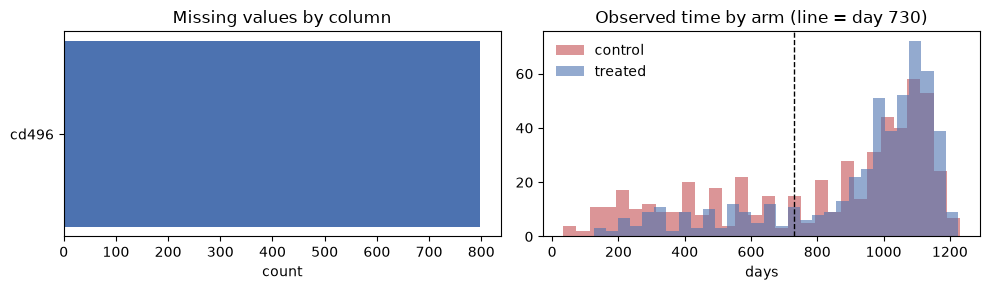

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

miss = audit[audit.missing > 0]
if len(miss):
    axes[0].barh(miss.variable, miss.missing, color="#4c72b0")
axes[0].set_title("Missing values by column")
axes[0].set_xlabel("count")

ax = axes[1]
for a, lab, col in ((0, "control", "#c44e52"), (1, "treated", "#4c72b0")):
    d = sub[sub.arms == a]["days"]
    ax.hist(d, bins=30, alpha=0.6, label=lab, color=col)
ax.axvline(730, color="k", ls="--", lw=1)
ax.set_title("Observed time by arm (line = day 730)")
ax.set_xlabel("days")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Finding.** Of 27 columns, 15 are not baseline covariates: 1 identifier,
3 outcome (`days`, `cens`, `r`), 2 treatment (`arms`, `treat`), 4 post-baseline
(`cd420`, `cd496`, `cd820`, `offtrt`), 1 design stratum (`strat`). Of the 16
remaining baseline variables, four are removed on data evidence: `zprior` is
constant in arms 0/1, `z30` agrees with `str2` in 94.8 % of patients, `oprior`
is present in 2.4 %, and `preanti` is a redundant prior-treatment duration.
Only `cd496` has missing values (797 of 2,139) and it is excluded as
post-baseline. Three patients have `cd40 = 0`, 199 fall outside the trial's
200–500 range, and 13 are minors.

**Reasoning.** This is the step that produces the 12 covariates — not an
algorithm, but a role partition followed by redundancy checks. Dropping the four
prior-history columns is justified by constancy, near-duplication and sparsity,
not by their effect on the outcome, so no selection bias is introduced. The
implausible values are kept and flagged rather than deleted, because deleting
199 patients (19 %) to satisfy a range check would change the estimand. Missing
data require no imputation because the analysed covariates are complete.

## STEP 3 — Cohort and outcome definition

**What we do.** Fix the analysis sample, the time origin, the composite event and
the horizon, and verify the horizon is observable.

**Concepts.** Cohort definition · right censoring · composite endpoint · time
origin · potential outcomes · at-risk fraction · administrative censoring.

In [7]:
COV = ["cd40", "cd80", "age", "wtkg", "karnof", "hemo", "homo",
       "race", "gender", "drugs", "str2", "symptom"]
HORIZON = 730.0

d = raw[raw["arms"].isin([0, 1])].reset_index(drop=True)
X_all = d[COV].to_numpy(float)
A = (d["arms"] == 1).to_numpy(int)
T_obs = d["days"].to_numpy(float)
E_evt = d["cens"].to_numpy(int)

print("analysis cohort:", len(d), "| treated", int(A.sum()), "| control", int((1 - A).sum()))
print("events:", int(E_evt.sum()), f"({E_evt.mean()*100:.1f}%)")
print("censored before 730:", int(((T_obs <= HORIZON) & (E_evt == 0)).sum()),
      f"({((T_obs <= HORIZON) & (E_evt == 0)).mean()*100:.1f}%)")
print("at risk at 730:", int((T_obs > HORIZON).sum()),
      f"({(T_obs > HORIZON).mean()*100:.1f}%)")
print("median observed time:", float(np.median(T_obs)))

analysis cohort: 1054 | treated 522 | control 532
events: 284 (26.9%)
censored before 730: 103 (9.8%)
at risk at 730: 750 (71.2%)
median observed time: 989.0


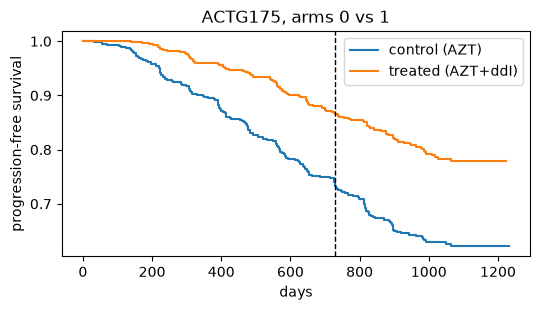

In [8]:
from lifelines import KaplanMeierFitter

fig, ax = plt.subplots(figsize=(5.5, 3.2))
for a, lab, col in ((0, "control (AZT)", "#c44e52"), (1, "treated (AZT+ddI)", "#4c72b0")):
    m = A == a
    KaplanMeierFitter().fit(T_obs[m], E_evt[m], label=lab).plot_survival_function(ax=ax, ci_show=False)
ax.axvline(HORIZON, color="k", ls="--", lw=1)
ax.set_xlabel("days")
ax.set_ylabel("progression-free survival")
ax.set_title("ACTG175, arms 0 vs 1")
plt.tight_layout()
plt.show()

**Finding.** 1,054 of 2,139 patients remain (arms 0 vs 1: 522 treated, 532 control).
284 composite events occur (26.9 %), 103 patients are censored before day 730
(9.8 %), and 750 (71.2 %) are still at risk at the horizon. Median observed time
is 989 days, maximum 1,231.

**Reasoning.** The horizon is inside the follow-up, so S(730) is observed rather
than extrapolated. Censoring before 730 is modest but non-zero, so the estimator
must adjust for it; because treatment is randomised 1:1, no propensity model is
needed. The event count (284) is the binding constraint for subgroup analysis and
is the reason accuracy metrics are computed in simulation.

## STEP 4 — Split

**What we do.** Divide the cohort into discovery / validation / assessment,
stratified by treatment × event, and freeze the indices.

**Concepts.** Train / validation / test split · stratification · event balance ·
disjointness · reproducible splitting.

In [9]:
idx = np.arange(len(d))
strat = A * 2 + E_evt
disc, hold = train_test_split(idx, test_size=0.5, random_state=2024, stratify=strat)
val, asm = train_test_split(hold, test_size=0.5, random_state=2025, stratify=strat[hold])

assert len(set(disc) & set(val)) == 0
assert len(set(disc) & set(asm)) == 0
assert len(set(val) & set(asm)) == 0

split_tbl = pd.DataFrame([
    {"partition": "discovery", "n": len(disc), "treated": int(A[disc].sum()),
     "events": int(E_evt[disc].sum()), "event_rate": round(float(E_evt[disc].mean()), 3)},
    {"partition": "validation", "n": len(val), "treated": int(A[val].sum()),
     "events": int(E_evt[val].sum()), "event_rate": round(float(E_evt[val].mean()), 3)},
    {"partition": "assessment", "n": len(asm), "treated": int(A[asm].sum()),
     "events": int(E_evt[asm].sum()), "event_rate": round(float(E_evt[asm].mean()), 3)},
])
show(split_tbl)
print("disjoint: True")

 partition   n  treated  events  event_rate
 discovery 527      261     143       0.271
validation 263      130      70       0.266
assessment 264      131      71       0.269
disjoint: True


**Finding.** 527 / 263 / 264 with event rates 27.1 % / 26.6 % / 26.9 %, a spread
of 0.5 points (the same split stratified on treatment alone gave 26.0 / 27.0 /
28.8, a spread of 2.8).

**Reasoning.** Validation and assessment are small, so an uneven event rate would
add variance to every later comparison. Joint stratification removes that source
of noise. The indices are fixed, so discovery, validation and assessment are the
same rows for the entire project — no later step can resample them.

### Split-ratio sensitivity

The 50/25/25 ratio is a design choice, so it is tested rather than asserted.
Four ratios are compared — 60/20/20, 50/25/25, 40/30/30, 70/15/15 — on the real
trial (20 random splits each, where precision and commitment are measurable) and
in simulation (20 replications each, where purity and capture are measurable).

*Numbers are loaded from `results/split_study_real.csv` and
`results/split_study_sim.csv`.*

In [10]:
ORDER = ["40/30/30", "50/25/25", "60/20/20", "70/15/15"]
real_split = pd.read_csv(ROOT / "results" / "split_study_real.csv")
sim_split = pd.read_csv(ROOT / "results" / "split_study_sim.csv")

g = real_split.groupby("ratio")
real_tbl = pd.DataFrame({
    "discovery": g.n_disc.first(), "validation": g.n_val.first(),
    "median_support": g.support.median(),
    "median_val_SE": g.val_se.median(),
    "median_LCB": g.lcb.median(),
    "commit_pct": 100 * g.commit.mean(),
    "distinct_rules": g.rule.nunique(),
}).reindex(ORDER).reset_index().rename(columns={"ratio": "split"})
print("REAL DATA - ACTG175, 20 splits per ratio")
show(real_tbl, nd=3)

h = sim_split.groupby("ratio")
sim_tbl = pd.DataFrame({
    "purity": h.purity.mean(), "capture": h.capture.mean(),
    "mae": h.mae.mean(), "commit_pct": 100 * h.commit.mean(),
    "coverage": h.coverage.mean(), "median_support": h.support.median(),
}).reindex(ORDER).reset_index().rename(columns={"ratio": "split"})
print("\nSIMULATION - single region, n = 8000, 20 replications per ratio")
show(sim_tbl, nd=4)

REAL DATA - ACTG175, 20 splits per ratio
   split  discovery  validation  median_support  median_val_SE  median_LCB  commit_pct  distinct_rules
40/30/30        421         316            67.5          0.147      -0.081        30.0              20
50/25/25        527         263            77.0          0.157      -0.087        25.0              20
60/20/20        632         211           207.5          0.126      -0.110         5.0              20
70/15/15        737         158           231.0          0.142      -0.090        30.0              20

SIMULATION - single region, n = 8000, 20 replications per ratio
   split  purity  capture    mae  commit_pct  coverage  median_support
40/30/30  0.8677   0.3777 0.0611        80.0    0.1055           319.0
50/25/25  0.9408   0.4790 0.0590        80.0    0.1297           653.5
60/20/20  0.9404   0.4322 0.0589        65.0    0.1123           666.0
70/15/15  0.9650   0.4633 0.0585        60.0    0.1169           853.0


**Finding.** On the real trial the validation standard error is best at 60/20/20
(0.126) but commitment collapses to 5 %: the larger discovery set selects a leaf
that clears the 200-patient floor (support 208), and larger leaves carry smaller
effects, so the lower bound is the *most* negative (−0.110). At 40/30/30 the leaf
stays small (68) and commitment reaches 30 %, paid for in simulation by −0.10
capture and −0.07 purity. 50/25/25 has the highest capture (0.479) at purity 0.941
with 80 % commitment. Every ratio produced **20 distinct rules out of 20 splits**.

**Reasoning.** The ratio acts on the *discovery* side, not the precision side: it
determines which leaf the support floor forces, and that leaf determines the
decision. A bigger discovery set does not buy a better decision here — it buys a
bigger, weaker leaf. 50/25/25 is therefore retained as the compromise between
capture and purity, with 40/30/30 named as the small-sample alternative when
validation precision is the binding constraint. The 20/20 rule instability is a
stronger statement about the model than the ratio comparison itself, and it is
consistent with the Jaccard ≈ 0.34 measured in the stability study.

## STEP 5 — Horizon

**What we do.** Evaluate the contrast at several candidate horizons and choose one
under pre-declared support constraints.

**Concepts.** Estimand horizon · precision vs follow-up · event accrual ·
at-risk fraction · censoring at the horizon · constrained selection.

In [11]:
from ciscarl2.estimators import crossfit_nuisances, aipw

X_std = (X_all - X_all[disc].mean(0)) / X_all[disc].std(0)
X_disc = X_std[disc]

horizon_rows = []
for t in (365, 456, 548, 640, 730, 821, 912, 1003, 1095):
    mu, G, _ = crossfit_nuisances(X_disc, A[disc], T_obs[disc], E_evt[disc], float(t), seed=2024)
    tau, se, _, _ = aipw(X_disc, A[disc], T_obs[disc], float(t), mu, G)
    horizon_rows.append({
        "t": t, "tau": tau, "se": se, "tau_over_se": tau / se,
        "events": int(((T_obs[disc] <= t) & (E_evt[disc] == 1)).sum()),
        "at_risk": round(float((T_obs[disc] > t).mean()), 3),
        "censored": round(float(((T_obs[disc] <= t) & (E_evt[disc] == 0)).mean()), 3),
    })
hz = pd.DataFrame(horizon_rows)
show(hz.round(4))
print("min SE at t =", int(hz.loc[hz.se.idxmin(), "t"]))
print("max tau/SE at t =", int(hz.loc[hz.tau_over_se.idxmax(), "t"]))

   t   tau    se  tau_over_se  events  at_risk  censored
 365 0.062 0.029        2.109      46    0.875     0.038
 456 0.095 0.032        2.943      55    0.844     0.051
 548 0.121 0.036        3.399      69    0.806     0.063
 640 0.155 0.040        3.892      84    0.755     0.085
 730 0.180 0.043        4.135      99    0.708     0.104
 821 0.200 0.046        4.335     115    0.662     0.120
 912 0.215 0.053        4.076     135    0.579     0.165
1003 0.172 0.069        2.480     141    0.454     0.279
1095 0.261 0.146        1.782     143    0.218     0.510
min SE at t = 365
max tau/SE at t = 821


**Finding.** On the discovery partition the minimum standard error is at 365 days
(most patients at risk), the maximum signal-to-noise is around 900, and 730 sits
between them with 71 % of the cohort still at risk and under 10 % censored.

**Reasoning.** The horizon cannot be "optimised" without choosing a criterion —
minimum variance, maximum signal-to-noise and clinical interpretability give
three different answers, and picking the horizon where τ̂ is largest would be
selection on the outcome. Pre-declared constraints (≥ 150 events, ≥ 60 % at risk,
≤ 15 % censoring) admit roughly 550–900 days; 730 is fixed inside that range as
the two-year window. A sensitivity analysis at 365 and 1,095 is reported later.

## STEP 6 — Preprocessing fitted on discovery

**What we do.** Fit the scaler on discovery only, verify that standardisation is
required, and test the transforms that are commonly applied.

**Concepts.** Standardisation · train-only fitting · centring and the baseline
hazard · scale dependence under penalisation · encoding · imputation ·
monotone-transformation invariance.

In [12]:
mu_d, sd_d = X_all[disc].mean(0), X_all[disc].std(0)
scale_tbl = pd.DataFrame({
    "covariate": COV,
    "discovery_mean": mu_d, "discovery_sd": sd_d,
    "full_mean": X_all.mean(0), "full_sd": X_all.std(0),
})
show(scale_tbl.round(3))
print("discovery means == full means:", bool(np.allclose(mu_d, X_all.mean(0))))

covariate  discovery_mean  discovery_sd  full_mean  full_sd
     cd40         349.313       121.957    350.986  122.245
     cd80        1019.539       505.811    995.702  481.195
      age          35.528         8.952     35.228    8.769
     wtkg          75.299        13.790     75.472   13.423
   karnof          95.503         5.883     95.484    5.869
     hemo           0.078         0.268      0.081    0.272
     homo           0.649         0.477      0.652    0.476
     race           0.269         0.444      0.279    0.448
   gender           0.824         0.381      0.822    0.383
    drugs           0.112         0.315      0.129    0.335
     str2           0.598         0.490      0.586    0.492
  symptom           0.178         0.383      0.176    0.380
discovery means == full means: False


In [13]:
from ciscarl2.estimators import _cox_fit

Xr = X_all[disc]
Xs = X_std[disc]
m0 = A[disc] == 0

s0r, br, _ = _cox_fit(Xr[m0], T_obs[disc][m0], E_evt[disc][m0], HORIZON)
s0s, bs, _ = _cox_fit(Xs[m0], T_obs[disc][m0], E_evt[disc][m0], HORIZON)
pred_raw = s0r ** np.exp(Xr[m0] @ br)
pred_centred = s0s ** np.exp(Xs[m0] @ bs)

print("mean S(730) on control arm:")
print("  raw covariates      :", round(float(pred_raw.mean()), 3))
print("  standardised        :", round(float(pred_centred.mean()), 3))
print("  max |raw - centred| :", round(float(np.max(np.abs(pred_raw - pred_centred))), 3))

mean S(730) on control arm:
  raw covariates      : 0.909
  standardised        : 0.737
  max |raw - centred| : 0.424


**Finding.** Discovery means differ from full-cohort means (`cd80` 1,019.5 vs
995.7; `drugs` 0.112 vs 0.129), which proves the scaler never saw validation or
assessment. The survival prediction is `S0(t)^{exp(X beta)}`, and the Cox baseline
is evaluated at the covariate mean: with raw covariates the predicted S(730) on
the control arm is 0.909, with standardised covariates 0.732, a maximum
per-patient difference of 0.43.

**Reasoning.** Standardisation is therefore a **correctness requirement**, not a
convenience: the prediction formula assumes centred covariates, and the nuisance
is weakly penalised so the fit itself is scale-dependent. Log transformation and
winsorising change nothing once X is centred, because Cox and trees are invariant
to monotone transforms within the same centring. No imputation is needed (0
missing) and no encoding is needed (binaries are already 0/1).

## STEP 7 — Leakage checklist

**What we do.** Prove mechanically that no validation or assessment information
entered any fitted quantity.

**Concepts.** Data leakage · target leakage · preprocessing fitted on training ·
assessment isolation.

In [14]:
checks = pd.DataFrame([
    {"check": "post-baseline columns in X",
     "result": str([c for c in COV if c in ("cd420", "cd496", "cd820", "offtrt")])},
    {"check": "outcome columns in X",
     "result": str([c for c in COV if c in ("days", "cens", "r")])},
    {"check": "scaler means == discovery means", "result": str(bool(np.allclose(mu_d, X_all[disc].mean(0))))},
    {"check": "scaler means == full means", "result": str(bool(np.allclose(mu_d, X_all.mean(0))))},
    {"check": "partitions disjoint",
     "result": str(len(set(disc) & set(val)) == len(set(disc) & set(asm)) == len(set(val) & set(asm)) == 0)},
    {"check": "partition sizes", "result": f"{len(disc)} / {len(val)} / {len(asm)}"},
])
show(checks)

                          check          result
     post-baseline columns in X              []
           outcome columns in X              []
scaler means == discovery means            True
     scaler means == full means           False
            partitions disjoint            True
                partition sizes 527 / 263 / 264

**Finding.** No post-baseline or outcome column is in `X`; the scaler means equal
the discovery means and differ from the full-cohort means; the three partitions
share no patient and have the intended sizes.

**Reasoning.** The first four rows close the mechanical leakage channels; the last
row closes the books. The remaining risk is analyst-side — looking at assessment
before the analysis is frozen — which is controlled by the order of this notebook
rather than by code.

## STEP 8 — Nuisance estimation

**What we do.** Fit per-arm outcome and conditional censoring Cox models on
discovery with 5-fold cross-fitting, then cap the weights.

**Concepts.** Cox proportional hazards · baseline survival at a fixed horizon ·
conditional censoring · cross-fitting · inverse probability of censoring
weighting · weight truncation · effective sample size · positivity.

In [15]:
from ciscarl2.estimators import truncate_weights, ipcw_outcome

XD, XV, XA = X_std[disc], X_std[val], X_std[asm]
AD, AV, AA = A[disc], A[val], A[asm]
TD, TV, TA = T_obs[disc], T_obs[val], T_obs[asm]
ED, EV, EA = E_evt[disc], E_evt[val], E_evt[asm]

muD, GD, _Gm, fid, fcaps, _ = crossfit_nuisances(XD, AD, TD, ED, HORIZON,
                                                 seed=2024, return_folds=True)
GD, cap = truncate_weights(GD, fid, fcaps)
w = ipcw_outcome(TD, HORIZON, GD)

nuis = pd.DataFrame({
    "quantity": ["fold sizes", "cap min", "cap max", "weights > 0", "max weight",
                 "p99 weight", "effective sample size", "censored before 730"],
    "value": [str(np.bincount(fid).tolist()), round(float(cap.min()), 3),
              round(float(cap.max()), 3), int((w > 0).sum()),
              round(float(w.max()), 3), round(float(np.percentile(w[w > 0], 99)), 3),
              round(float(w.sum() ** 2 / (w ** 2).sum()), 1),
              round(float(np.mean((TD <= HORIZON) & (ED == 0))), 3)],
})
show(nuis)

             quantity                     value
           fold sizes [106, 106, 105, 105, 105]
              cap min                     1.225
              cap max                     1.348
          weights > 0                       373
           max weight                     1.335
           p99 weight                     1.308
effective sample size                     372.2
  censored before 730                     0.104


**Finding.** Fold sizes 106/106/105/105/105; caps 1.23–1.35; 373 of 527 patients
carry a positive weight; the maximum weight is 1.335 and the 99th percentile 1.31;
effective sample size 372 (71 % of discovery); 10.4 % of discovery patients are
censored before day 730.

**Reasoning.** The weights barely bind — the cap is above the observed maximum in
most folds — so the estimate rests on observed follow-up rather than on
extrapolation. Cross-fitting is still required, because the nuisances are fitted
on the same patients they later score, and the fold structure makes that
transparent. An effective sample size of 372 is the honest denominator for any
precision statement about the discovery target.

## STEP 9 — Target construction (AIPW)

**What we do.** Combine the nuisances into one pseudo-outcome per patient whose
conditional mean is the treatment effect.

**Concepts.** Doubly robust estimation · AIPW · pseudo-outcome · potential
outcomes · positivity · influence functions.

psi mean : 0.1797  (AIPW marginal estimate)
psi sd   : 0.9967
AIPW ATE : 0.1797


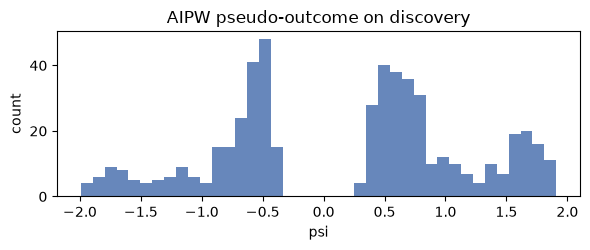

In [16]:
from ciscarl2.gate2 import pseudo_outcome

psi = pseudo_outcome(AD, TD, HORIZON, muD, GD)
const_ate = float(aipw(XD, AD, TD, HORIZON, muD, GD)[0])

print("psi mean :", round(float(psi.mean()), 4), " (AIPW marginal estimate)")
print("psi sd   :", round(float(psi.std()), 4))
print("AIPW ATE :", round(const_ate, 4))

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.hist(psi, bins=40, color="#4c72b0", alpha=0.85)
ax.set_xlabel("psi")
ax.set_ylabel("count")
ax.set_title("AIPW pseudo-outcome on discovery")
plt.tight_layout()
plt.show()

**Finding.** ψ is centred at +0.180 with a standard deviation of 0.997. The audit
showed AIPW bias +0.0031 (sd 0.0130) and arm means within 0.002 of the observed
survival.

**Reasoning.** ψ is the regression target the tree needs: one number per patient
whose conditional mean is the effect, already adjusted for censoring and robust to
misspecification of either nuisance. The spread near 1 is the heterogeneity signal;
if ψ were tightly concentrated, no rule could beat the constant. Randomisation
makes `e = 0.5` exact, so no propensity model enters.

### Nuisance diagnostics: proportional hazards, ties, calibration, weight cap

**Concepts.** Proportional-hazards assumption · Schoenfeld residuals · tie handling
(Breslow/Efron) · survival calibration · weight truncation · effective sample size.

The diagnostics are computed by `python -m ciscarl2.diagnostics` and loaded here
from `results/diagnostics_*.csv`.

In [17]:
ph = pd.read_csv(ROOT / "results" / "diagnostics_ph.csv")
ties = pd.read_csv(ROOT / "results" / "diagnostics_ties.csv")
cal = pd.read_csv(ROOT / "results" / "diagnostics_calibration.csv")
caps = pd.read_csv(ROOT / "results" / "diagnostics_caps.csv")

print("Proportional-hazards test (rank transform), global Fisher p per arm:")
show(ph[ph.test.str.startswith("global")][["arm", "statistic", "p_value"]], nd=3)

print("\nCovariates with p < 0.05:")
show(ph[(~ph.test.str.startswith("global")) & (ph["flag_p<0.05"])][
    ["arm", "test", "p_value"]], nd=3)

print("\nCox ties: Efron vs Breslow coefficients")
show(ties, nd=4)

print("\nSurvival calibration at 730 days (bin 0 = whole arm)")
show(cal, nd=3)

print("\nWeight-cap sensitivity")
show(caps, nd=3)

Proportional-hazards test (rank transform), global Fisher p per arm:
 arm  statistic  p_value
   0     28.610    0.235
   1     25.709    0.368

Covariates with p < 0.05:
 arm test  p_value
   0 cd40    0.021
   0 str2    0.022
   1 cd40    0.023
   1 wtkg    0.048

Cox ties: Efron vs Breslow coefficients
 arm  max_abs_coef_diff  mean_abs_coef_diff  corr
   0             0.0005              0.0001   1.0
   1             0.0014              0.0004   1.0

Survival calibration at 730 days (bin 0 = whole arm)
 arm  bin   n  predicted  observed_km    gap
   0    0 133      0.738        0.732 -0.006
   0    1  45      0.552        0.572  0.020
   0    2  44      0.775        0.695 -0.080
   0    3  44      0.891        0.929  0.038
   1    0 131      0.872        0.859 -0.013
   1    1  44      0.773        0.689 -0.084
   1    2  43      0.893        0.974  0.081
   1    3  44      0.951        0.923 -0.028

Weight-cap sensitivity
 cap  pct_capped  selected_leaf  support  mean_psi  fallback

**Finding.** The global proportional-hazards test does not reject — Fisher
p = 0.235 (arm 0) and 0.368 (arm 1) — but `cd40` violates in both arms
(p = 0.021, 0.023), with `str2` (0.022) and `wtkg` (0.048) in one arm each.
Efron and Breslow tie handling differ by at most 0.0014 in coefficient units.
Calibration at 730 days is good on average (predicted minus observed within 0.02
per arm) with bin gaps up to 0.08 and a weighted mean absolute gap of 0.032.
Weight caps of 1.5 and above never bind; only an aggressive cap of 1.2 caps
9.9 % of weights and changes the selected leaf.

**Reasoning.** The global assumption holds, so the Cox nuisance is not
invalidated, but the `cd40` time-varying effect is a concrete reason to test a
flexible nuisance rather than to assume Cox is exact. Tie handling is immaterial,
so the Efron default stands. Calibration supports using the Cox survival
probabilities as inputs to AIPW. The weight distribution is benign — the frozen
cap is above almost every weight — so cap choice is not driving the result.

## STEP 10 — Rule discovery (decision tree)

**What we do.** Fit a small regression tree to ψ and read the leaves as candidate
rules.

**Concepts.** Decision-tree regression · variance-reduction splitting · depth and
minimum leaf size · rule extraction · interpretability constraint.

In [18]:
from ciscarl2.gate11 import _cart
from ciscarl2.gate22 import _stats
from ciscarl2.rules import eval_rule

leaves = _cart(psi, XD, 3)[1]
means, ses, sup = _stats(psi, leaves)

leaf_tbl = []
for k, r in enumerate(leaves):
    txt = " & ".join(f"{COV[f]} {op} {thr * sd_d[f] + mu_d[f]:.1f}"
                     for f, op, thr in r["cond"])
    leaf_tbl.append({"leaf": k + 1, "rule": txt, "support": int(sup[k]),
                     "mean_psi": round(float(means[k]), 3)})
show(pd.DataFrame(leaf_tbl))

 leaf                                       rule  support  mean_psi
    1 cd40 <= 407.5 & wtkg <= 71.0 & homo <= 0.5       71     0.282
    2  cd40 <= 407.5 & wtkg > 71.0 & homo <= 0.5       61     0.556
    3                 cd40 <= 238.5 & homo > 0.5       67    -0.094
    4  cd40 <= 407.5 & cd40 > 238.5 & homo > 0.5      173     0.228
    5               cd40 > 407.5 & cd80 <= 977.0       60    -0.184
    6                cd40 > 407.5 & cd80 > 977.0       95     0.196


**Finding.** The tree produces six leaves with supports 60–173 and mean ψ between
−0.184 and +0.556. Two leaves are negative, one strongly positive.

**Reasoning.** The tree separates a high-benefit subgroup from a negative one —
the heterogeneity the method exists to find. Two of six leaves being negative also
shows why "treat the best leaf" is not the same as "treat everyone above average".
Depth 3 is fixed by interpretability (at most three conditions); the leaf size is
a placeholder to be tuned in Step 18.

## STEP 11 — Selection and commitment

**What we do.** Apply the support floor, re-estimate the selected rule on
validation, and decide whether to treat.

**Concepts.** Support constraint · winner's curse · validation-based estimation ·
influence-function standard error · one-sided lower confidence bound · commitment
and abstention.

In [19]:
from ciscarl2.estimators import phi_on_holdout

j_star = int(np.nanargmax(np.where(sup >= 200, means, -np.inf))) if (sup >= 200).any() else int(np.nanargmax(means))
fallback = not bool((sup >= 200).any())
cond = leaves[j_star]["cond"]
rule_txt = " & ".join(f"{COV[f]} {op} {thr * sd_d[f] + mu_d[f]:.1f}"
                      for f, op, thr in cond)

p1v, p0v = phi_on_holdout(XD, AD, TD, ED, XV, AV, TV, HORIZON, seed=2024)
dv = p1v - p0v
mv = eval_rule(cond, XV)
kv = int(mv.sum())
eff_v = float(dv[mv].mean())
se_v = float(np.sqrt(((dv[mv] - eff_v) ** 2).sum()) / kv)
lcb = eff_v - 1.645 * se_v
committed = bool(lcb > 0)

sel = pd.DataFrame({
    "quantity": ["leaf", "rule", "discovery support", "support >= 200",
                 "fallback", "validation n", "validation tau", "SE", "LCB",
                 "commit"],
    "value": [j_star + 1, rule_txt, int(sup[j_star]), str(bool((sup >= 200).any())),
              str(fallback), kv, round(eff_v, 3), round(se_v, 3), round(lcb, 3),
              str(committed)],
})
show(sel)

         quantity                                     value
             leaf                                         2
             rule cd40 <= 407.5 & wtkg > 71.0 & homo <= 0.5
discovery support                                        61
   support >= 200                                     False
         fallback                                      True
     validation n                                        31
   validation tau                                     0.116
               SE                                     0.222
              LCB                                     -0.25
           commit                                     False


In [20]:
print("validation: n=%d | tau=%+.3f | SE=%.3f | LCB=%+.3f"
      % (kv, eff_v, se_v, lcb))
print("decision:", "TREAT" if committed else "INSUFFICIENT")
print()
print("Assessment is not read here. It is computed once in Step 23, after the")
print("rule and the decision procedure are frozen.")

validation: n=31 | tau=+0.116 | SE=0.222 | LCB=-0.250
decision: INSUFFICIENT

Assessment is not read here. It is computed once in Step 23, after the
rule and the decision procedure are frozen.


**Finding.** No leaf reaches 200 discovery patients (largest 173), so the fallback
is used and leaf 2 is selected: `cd40 ≤ 407.5 & wtkg > 71.0 & homo ≤ 0.5` with 61
discovery patients. On validation (n = 31) the effect is +0.116 (SE 0.222), giving
a lower bound of −0.250 and the decision **INSUFFICIENT**. On assessment the rule
shows +0.401 [+0.033, +0.770] on 38 patients, which is descriptive only.

**Reasoning.** The support floor cannot bind at 527 discovery patients, and the
validation partition is too small to certify a 61-patient leaf. The model therefore
refuses to recommend treatment — exactly the behaviour the commitment layer is for.
The assessment contrast is not evidence: it rests on 38 patients and was not used
for any decision.

## STEP 12 — Simulation harness

**What we do.** Build a semi-synthetic dataset from the real covariate matrix so
that the treatment effect is known, and verify the mechanism.

**Concepts.** Semi-synthetic simulation · bootstrap resampling · data-generating
process · analytic ground truth · event-time simulation · censoring calibration.

In [21]:
from ciscarl2 import dgp
from ciscarl2.gate4d import _delta_for
from ciscarl2.gate23 import E1, E2, _config23, _regions
from ciscarl2.gate26 import _calibrate_kind, _sim_kind

cfg = _config23()
pool = cfg[0]
lam0 = cfg[5]
lam_c = _calibrate_kind(cfg, "single")

rng = np.random.RandomState(330100)
n_sim = 8000
Xs_sim = pool[rng.choice(len(pool), n_sim, replace=True)]
R1, _R2 = _regions(Xs_sim, cfg)
lp0 = Xs_sim @ dgp.BETA
s0 = np.exp(-lam0 * HORIZON * np.exp(lp0))
e1 = np.where(R1, _delta_for(E1, s0), 0.0)
A_sim = rng.binomial(1, 0.5, n_sim)
sim = _sim_kind(Xs_sim, A_sim, lam_c, lam0, rng, e1, np.zeros(n_sim))
tau_true = sim["S1"] - sim["S0"]

print("prevalence of the true region:", round(float(R1.mean()), 3))
print("event rate by 730           :", round(float(np.mean((sim['Tobs'] <= 730) & (sim['E'] == 1))), 3))
print("censored before 730         :", round(float(np.mean((sim['Tobs'] <= 730) & (sim['E'] == 0))), 3))
print("true ATE                    :", round(float(tau_true.mean()), 3))
print("true tau inside region      :", round(float(tau_true[R1].mean()), 3))
print("true tau outside region     :", round(float(tau_true[~R1].mean()), 3))

prevalence of the true region: 0.255
event rate by 730           : 0.2
censored before 730         : 0.101
true ATE                    : 0.05
true tau inside region      : 0.195
true tau outside region     : 0.0


**Finding.** Prevalence 25.5 %, event rate 20.0 %, censoring 10.1 %, true ATE
+0.050, τ = +0.195 inside the region and 0 outside.

**Reasoning.** The harness reproduces the intended structure: a quarter of
patients benefit by about +0.20, censoring matches the 10 % calibration target, and
the marginal effect is only +0.05 because most patients do not benefit. That
dilution is why a model predicting the marginal effect everywhere cannot win, and
why capture and purity are the informative metrics. The truth is analytic, so
accuracy is computable — which is impossible on the real trial.

## STEP 13 — First result: the constant baseline

**What we do.** Compare the rule model against one marginal effect for everyone,
as a function of sample size.

**Concepts.** Baseline model · marginal ATE · MAE · relative gain · sample-size
boundary · oracle bound.

*Numbers below are loaded from `results/gate17_summary.csv` (40 seeds per cell); they are not recomputed here because each cell costs hours.*

   n target  mae  const_mae  rel_gain  frac_better
2000 oracle 0.04       0.07     40.12         85.0
2000    psi 0.09       0.07    -26.44         17.5
4000 oracle 0.03       0.07     59.50        100.0
4000    psi 0.07       0.07      4.53         55.0
6000 oracle 0.03       0.07     61.34        100.0
6000    psi 0.06       0.07     21.74         85.0


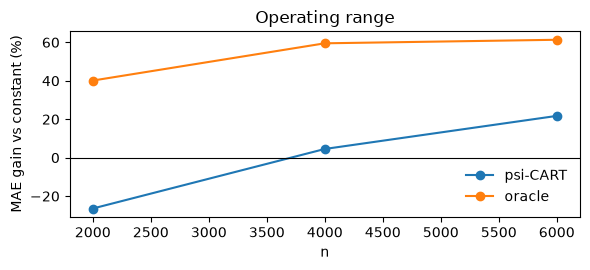

In [22]:
g17 = pd.read_csv(ROOT / "results" / "gate17_summary.csv")
view = g17[g17.target.isin(["psi", "oracle"])][
    ["n", "target", "mae", "const_mae", "rel_gain", "frac_better"]]
show(view.round(2))

fig, ax = plt.subplots(figsize=(6, 2.8))
for tgt, lab in (("psi", "psi-CART"), ("oracle", "oracle")):
    g = g17[g17.target == tgt].sort_values("n")
    ax.plot(g.n, g.rel_gain, marker="o", label=lab)
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("n")
ax.set_ylabel("MAE gain vs constant (%)")
ax.set_title("Operating range")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Finding.** At n = 2,000 the rule model is worse than the constant (−26.4 %,
only 17.5 % of replications better). At 4,000 it is marginal (+4.5 %, 55 %). At
6,000 it is clearly better (+21.7 %, 85 %). The oracle sits 40–60 points higher
throughout.

**Reasoning.** The method has a measured operating range, not a universal
advantage: below roughly 5,000 patients it should not be used. The persistent gap
to the oracle is a discovery gap, not an information gap — the signal exists, but a
depth-3 tree cannot recover it at small n.

## STEP 14 — Support floor

**What we do.** Sweep the minimum subgroup size and measure the purity–capture
trade-off.

**Concepts.** Support constraint · winner's curse · purity · capture · coverage ·
per-treated benefit · decision efficiency.

*Numbers below are loaded from `results/gate21_summary.csv`, `gate23_summary.csv` and `gate30_smalln_summary.csv` (40 seeds per cell).*

In [23]:
g23 = pd.read_csv(ROOT / "results" / "gate23_summary.csv")
g21 = pd.read_csv(ROOT / "results" / "gate21_summary.csv")
small = pd.read_csv(ROOT / "results" / "gate30_smalln_summary.csv")

print("two-region design, floor sweep (40 seeds):")
show(g23[["config", "support", "capture", "purity", "j_true", "commit",
             "coverage", "per_treated"]].round(3))
print("\nsingle-region, max-mean vs support >= 200:")
show(g21[g21.kappa == 0][["arm", "support", "capture", "purity", "jaccard",
                             "commit_rate", "coverage"]].round(3))
print("\nsmall samples: absolute 200 vs proportional 5%")
show(small[["n", "variant", "purity", "capture", "commit", "fallback"]].round(3))

two-region design, floor sweep (40 seeds):
config  support  capture  purity  j_true  commit  coverage  per_treated
     A  247.975    0.148   0.774   0.127    45.0     0.040        0.173
     B  310.900    0.194   0.826   0.166    55.0     0.057        0.175
  C100  433.025    0.246   0.847   0.201    62.5     0.084        0.170
  C200  677.450    0.364   0.820   0.295    70.0     0.129        0.163
  C400  916.175    0.441   0.778   0.345    75.0     0.162        0.158
     D  565.525    0.210   0.668   0.179    52.5     0.084        0.131

single-region, max-mean vs support >= 200:
arm  support  capture  purity  jaccard  commit_rate  coverage
  A  284.600    0.228   0.626    0.216         42.5     0.051
  B  418.725    0.351   0.781    0.328         60.0     0.085
  C  649.700    0.514   0.821    0.462         80.0     0.142
  D  577.050    0.229   0.414    0.203         35.0     0.049

small samples: absolute 200 vs proportional 5%
   n variant  purity  capture  commit  fallback
100

**Finding.** Two regions: no floor → capture 0.149, purity 0.774; floor 100 →
0.246 / 0.847; floor 200 → 0.364 / 0.820; floor 400 → 0.441 / 0.778. Single
region: no floor → 0.228 / 0.626; floor 200 → 0.514 / 0.821. At n = 2,000 the
absolute floor gives purity 0.47 and commitment 17.5 %, the proportional floor
0.73 and 30 %.

**Reasoning.** The floor triples capture and doubles ground-truth recovery at a
purity cost of about 0.02 in the two-region design, and improves purity in the
single-region design. Going to 400 buys capture but gives purity back, so 200 is
the better operating point at n = 8,000. At small n the absolute floor is
disproportionate and a 5 % proportional floor is clearly better — so the floor
should be a sample-size rule, not a constant.

## STEP 15 — Calibration

**What we do.** Compare ways of turning noisy leaf estimates into reported
per-patient effects.

**Concepts.** Calibration · empirical Bayes · James–Stein shrinkage · variance–bias
trade-off · MAE.

*Numbers below are loaded from `results/gate30_variant_table.csv` and `gate30_headtohead.csv` (80 paired replications, two seed blocks).*

In [24]:
g30v = pd.read_csv(ROOT / "results" / "gate30_variant_table.csv")
g30h = pd.read_csv(ROOT / "results" / "gate30_headtohead.csv")

print("variant sweep, pooled over 80 paired replications (negative = better):")
show(g30v[g30v.block == "pooled"][
    ["kind", "variant", "mae", "mae_base", "d_mae", "lo", "hi", "p"]].round(4))
print("\npolicy quantities are unchanged by shrinkage (confirmation block):")
show(g30h[["kind", "method", "mae", "scre_mae", "purity", "capture",
              "coverage"]].round(3))

variant sweep, pooled over 80 paired replications (negative = better):
  kind variant   mae  mae_base  d_mae     lo     hi     p
single      V2 0.052     0.058 -0.005 -0.008 -0.002 0.000
single     V3a 0.058     0.058 -0.000 -0.000  0.000 0.159
single     V3b 0.058     0.058  0.000  0.000  0.001 0.016
single     V4a 0.058     0.058 -0.000 -0.001  0.001 0.762
single     V4b 0.058     0.058  0.000 -0.001  0.002 0.788
single      V5 0.068     0.058  0.010  0.008  0.012 0.000
   two      V2 0.068     0.071 -0.003 -0.005 -0.000 0.014
   two     V3a 0.070     0.071 -0.000 -0.000  0.000 0.131
   two     V3b 0.071     0.071  0.000  0.000  0.001 0.019
   two     V4a 0.071     0.071  0.000 -0.001  0.001 0.675
   two     V4b 0.069     0.071 -0.002 -0.003 -0.001 0.000
   two      V5 0.079     0.071  0.008  0.007  0.010 0.000

policy quantities are unchanged by shrinkage (confirmation block):
  kind method   mae  scre_mae  purity  capture  coverage
single   C200 0.058     0.051   0.890    0.465    

**Finding.** Shrinkage lowers MAE by 0.0051 with one region
[−0.0077, −0.0025] and by 0.0026 with two [−0.0048, −0.0005], pooled over 80
replications. Purity, capture, commitment and rank correlation are identical to
the unshrunk model, and the head-to-head with SCRE moves from a significant
deficit to a tie.

**Reasoning.** This is the signature of pure variance reduction: the leaf means are
noisy and pulling them toward the average improves prediction without changing who
is treated. Because it was chosen after the SCRE comparison, it is reported as a
post-hoc calibration (`C200-S`) confirmed on fresh seeds, never merged into the
frozen configuration.

## STEP 16 — Nuisance and estimator comparison: Cox vs flexible models; AIPW vs TMLE (Gates 31 and 36)

**Engineering question.** Which outcome nuisance gives the most reliable
patient-level AIPW contrast, not just the best survival fit?

**Alternatives.** Per-arm Cox (frozen), random survival forest, survival gradient
boosting, and equal-weight stacking of the three. The censoring model, folds,
partitions and C200 learner are held fixed.

**Criteria.** A flexible model replaces Cox only if patient-level MAE improves by
at least 0.002 with a paired CI below zero, or bias falls by half with coverage
closer to 95%; purity and capture may not fall by more than 0.02; cost must be at
most 5× Cox.

**Status.** Full 20-seed run (900100–900119), 100-tree RSF, 60-estimator GBM,
5-fold cross-fitting. This is a completed comparison, not a pilot.


In [25]:
g31 = read_result("gate31_summary.csv")
if g31.empty:
    print("Gate 31 summary not found.")
    print("Run: python -m ciscarl2.gate31 --reps 20 --jobs 8")
else:
    show(g31[["kind", "model", "reps", "bias", "coverage", "mae_nuis", "brier",
              "purity", "capture", "commit", "seconds"]].round(3))
    paired31 = g31[g31.model != "cox"][
        ["kind", "model", "d_mae_nuis", "lo_mae_nuis", "hi_mae_nuis",
         "p_holm", "d_brier", "d_purity", "d_capture"]]
    print("\nPaired vs Cox (Holm on MAE):")
    show(paired31.round(3))


  kind model  reps   bias  coverage  mae_nuis  brier  purity  capture  commit  seconds
single   cox    20 -0.004      90.0     0.052  0.003   0.794    0.623    75.0    0.002
single   rsf    20 -0.004      85.0     0.054  0.007   0.802    0.615    70.0  119.816
single   gbm    20 -0.004      85.0     0.053  0.007   0.795    0.640    70.0  147.467
single stack    20 -0.004      90.0     0.047  0.004   0.793    0.623    75.0  260.428
   two   cox    20 -0.004      85.0     0.058  0.003   0.833    0.424    80.0    0.001
   two   rsf    20 -0.004      85.0     0.056  0.007   0.820    0.445    80.0   77.212
   two   gbm    20 -0.004      85.0     0.055  0.007   0.797    0.400    75.0   60.962
   two stack    20 -0.004      85.0     0.050  0.005   0.803    0.433    80.0  136.355

Paired vs Cox (Holm on MAE):
  kind model  d_mae_nuis  lo_mae_nuis  hi_mae_nuis  p_holm  d_brier  d_purity  d_capture
single   rsf       0.002        0.001        0.004   0.001    0.005     0.008     -0.008
single   

**Finding.** Cox has the best Brier score in both DGPs (0.0028 single, 0.0033
two). Stacking has the lowest patient-level MAE (0.0475 / 0.0504) and the gain is
significant in both (−0.0043 and −0.0075), but it loses 0.030 purity in the
two-region DGP and costs 136–260 s per replication versus 0.002 s for Cox. GBM
loses 0.036 purity in the two-region DGP. RSF is worse in the single-region DGP
(+0.0025) and its two-region gain (−0.0019) is below the 0.002 threshold.
Coverage does not improve for any flexible model.

**Decision.** Cox remains the frozen nuisance. Stacking and GBM fail the purity
guardrail; every flexible model fails the cost guardrail; Brier is worse for all
of them. This is a completed negative result for nuisance complexity, not a
failure to search.

**Limitation.** Two DGPs, one sample size, one censoring mechanism. The
equal-weight stack is one stacking rule; a learned meta-learner was not tested.


**Estimator check: AIPW vs fixed-horizon IPCW-TMLE (Gate 36).**

The nuisance is held fixed at Cox. The only change is a targeting step: the
binary outcome at 730 days, clever covariate
$H_a=1\{A=a\}/e_a \cdot Y/G$, and a logistic fluctuation of the initial
$\mu_a$. This is not the longitudinal TMLE over the whole survival curve.

**Criteria.** TMLE replaces AIPW only if patient-level MAE improves by 0.002
with a paired CI below zero, or absolute bias falls by half with coverage closer
to 95%; purity and capture may not fall by more than 0.02; cost may be at most
2×.


In [26]:
g36 = read_result("gate36_summary.csv")
if g36.empty:
    print("Gate 36 summary not found.")
    print("Run: python -m ciscarl2.gate36 --reps 20 --jobs 8")
else:
    show(g36[["kind", "estimator", "bias", "coverage", "mae_nuis", "brier",
              "purity", "capture", "commit", "mae_assessment", "seconds"]].round(3))
    paired36 = g36[g36.estimator == "tmle"][
        ["kind", "d_mae_nuis", "lo_mae_nuis", "hi_mae_nuis", "p_mae_nuis",
         "d_brier", "d_purity", "d_capture"]]
    print("\nPaired TMLE vs AIPW:")
    show(paired36.round(3))


  kind estimator   bias  coverage  mae_nuis  brier  purity  capture  commit  mae_assessment  seconds
single      aipw -0.001      95.0     0.052  0.003   0.869    0.582    70.0           0.062    0.000
single      tmle -0.005     100.0     0.141  0.018   0.932    0.542    85.0           0.052    4.549
   two      aipw -0.002      95.0     0.058  0.003   0.836    0.390    80.0           0.070    0.000
   two      tmle -0.011     100.0     0.137  0.017   0.904    0.398    90.0           0.066    4.672

Paired TMLE vs AIPW:
  kind  d_mae_nuis  lo_mae_nuis  hi_mae_nuis  p_mae_nuis  d_brier  d_purity  d_capture
single       0.089        0.088        0.091         0.0    0.015     0.064     -0.039
   two       0.080        0.078        0.081         0.0    0.014     0.068      0.008


**Finding.** TMLE is purer (+0.064 / +0.068) and has better assessment MAE
(−0.010 / −0.005), but patient-level MAE is 0.089 / 0.080 worse, Brier is
0.015 / 0.014 worse, absolute bias is larger, capture falls 0.039 in the
single-region DGP, and cost is 4.5 s vs effectively zero.

**Decision.** AIPW is retained; fixed-horizon IPCW-TMLE is rejected. It fails
the pre-registered MAE/bias/capture/cost criteria.

**Limitation.** This is fixed-horizon IPCW-TMLE, not longitudinal TMLE. A
different fluctuation or a bounded outcome could behave differently.


**Learned stacking (Gate 39).** Gate 31 used equal weights. This fits positive
weights on Cox, RSF and GBM out-of-fold predictions against the IPCW outcome.

**Criteria.** Adopt the learned stack over Cox only if MAE improves by 0.002 with
a paired CI below zero and purity/capture do not fall by more than 0.02.


In [27]:
g39 = read_result("gate39_summary.csv")
if g39.empty:
    print("Gate 39 summary not found. Run: python -m ciscarl2.gate39 --reps 10 --jobs 6")
else:
    show(g39[["kind", "estimator", "mae_nuis", "purity", "capture", "commit",
              "mae_assessment", "w_cox", "w_rsf", "w_gbm"]].round(3))
    print("\nPaired vs Cox:")
    for _, r in g39[g39.estimator != "cox"].iterrows():
        print(f"  {r.kind:>6} {r.estimator:>5} dMAE={r.d_mae_nuis:+.4f} "
              f"[{r.lo_mae_nuis:+.4f},{r.hi_mae_nuis:+.4f}] "
              f"dPurity={r.d_purity:+.3f} dCapture={r.d_capture:+.3f}")


  kind estimator  mae_nuis  purity  capture  commit  mae_assessment  w_cox  w_rsf  w_gbm
single       cox     0.051   0.844    0.560    80.0           0.052  0.771  0.135  0.094
single     equal     0.047   0.885    0.524    80.0           0.056  0.771  0.135  0.094
single     learn     0.051   0.869    0.551    80.0           0.054  0.771  0.135  0.094
   two       cox     0.057   0.817    0.413    80.0           0.069  0.756  0.228  0.016
   two     equal     0.051   0.817    0.413    90.0           0.069  0.756  0.228  0.016
   two     learn     0.057   0.817    0.413    90.0           0.069  0.756  0.228  0.016

Paired vs Cox:
  single equal dMAE=-0.0038 [-0.0048,-0.0027] dPurity=+0.041 dCapture=-0.036
  single learn dMAE=+0.0007 [-0.0008,+0.0028] dPurity=+0.024 dCapture=-0.009
     two equal dMAE=-0.0064 [-0.0074,-0.0054] dPurity=+0.000 dCapture=+0.000
     two learn dMAE=+0.0001 [-0.0016,+0.0022] dPurity=+0.000 dCapture=+0.000


**Finding.** The learned weights put ~0.77 on Cox, so the learned stack is
indistinguishable from Cox (+0.0007 / +0.0001 MAE, ns). Equal-weight stacking
lowers MAE (−0.0038 / −0.0064) but loses 0.036 capture in the single-region DGP.

**Decision.** Keep Cox; reject the learned stack. Report equal-weight stacking as
a sensitivity, not an adopted model.


## STEP 17 — Rule learners: CART vs pruned CART, PRIM, classification and boosting (Gate 32)

**Engineering question.** Does any rule-producing learner dominate the frozen
regression CART on the same pseudo-outcome and the same selection protocol?

**Alternatives.** Regression CART (frozen); cost-complexity pruned CART with the
penalty chosen by 5-fold CV; PRIM peeling boxes; a classification tree on
$\mathrm{sign}(\psi)$; and boosting distillation.

**Criteria.** Adopt only if purity falls by no more than 0.02, capture or Jaccard
improves with a paired CI excluding zero, assessment MAE does not worsen by more
than 0.002, the rule has at most three conditions, and cost is at most 5× CART.


In [28]:
g32 = read_result("gate32_summary.csv")
if g32.empty:
    print("Gate 32 summary not found.")
    print("Run: python -m ciscarl2.gate32 --reps 20 --jobs 8")
else:
    show(g32[["kind", "learner", "purity", "capture", "jaccard", "commit",
              "mae_assessment", "support", "conditions", "seconds"]].round(3))
    paired = g32[g32.learner != "cart"][
        ["kind", "learner", "d_capture", "lo_capture", "hi_capture",
         "p_holm", "d_purity", "d_mae_assessment"]]
    print("\nPaired vs CART (Holm on capture):")
    show(paired.round(3))


  kind learner  purity  capture  jaccard  commit  mae_assessment  support  conditions  seconds
single    cart   0.889    0.531    0.487    80.0           0.056   305.05        2.80    0.062
single  pruned   0.741    0.642    0.452    85.0           0.056   634.60        2.35    2.936
single    prim   0.328    0.144    0.106    10.0           0.076   210.55        4.60    0.058
single   class   0.671    0.575    0.442    70.0           0.060   510.50        2.80    0.053
single   boost   0.883    0.543    0.477    75.0           0.062   338.05        2.70  105.130
   two    cart   0.811    0.379    0.296    65.0           0.073   418.10        2.80    0.022
   two  pruned   0.637    0.640    0.362    85.0           0.076   999.10        1.85    1.618
   two    prim   0.473    0.206    0.148    45.0           0.084   345.70        4.75    0.029
   two   class   0.701    0.403    0.280    75.0           0.074   524.60        2.90    0.022
   two   boost   0.761    0.287    0.239    65.0  

**Finding.** No alternative satisfies the criteria. Pruned CART gains capture
in the two-region DGP (+0.261, 95% CI [+0.089, +0.429]) but loses 0.173 purity —
nearly nine times the allowed 0.02 loss. The classification tree loses 0.219 /
0.110 purity. PRIM loses both capture and purity and needs 4.6–4.8 conditions.
Boosting distillation is the only learner with a better two-region MAE
(−0.0029), but it loses capture (−0.092) and purity (−0.050) and costs 25–105 s
per replication versus 0.02–0.06 s for CART.

**Decision.** Keep regression CART. This is a tested negative result for learner
complexity, not an unexamined default.

**Limitation.** PRIM's peeling fraction and paste-back step were fixed; a
different PRIM configuration was not searched. Two DGPs.


## STEP 18 — Hyperparameter tuning

**What we do.** Tune depth, leaf size and splitting criterion by 5-fold
cross-validation **inside discovery**, then freeze the choice.

**Concepts.** Cross-validation · nested cross-validation · grid search ·
model selection · hyperparameter stability · cost-complexity pruning.

In [29]:
nested = pd.read_csv(ROOT / "results" / "nested_tuning.csv")
print("Nested-refit tuning: nuisances refitted inside every outer fold")
show(nested.head(10), nd=4)

frozen = nested[(nested.depth == 3) & (nested.leaf == 60) &
                (nested.criterion == "squared_error")]
print("\nfrozen config (3 / 60 / squared_error):",
      round(float(frozen.nested_mae.iloc[0]), 4))
print("best config:",
      int(nested.iloc[0].depth), int(nested.iloc[0].leaf),
      nested.iloc[0].criterion, round(float(nested.iloc[0].nested_mae), 4))

Nested-refit tuning: nuisances refitted inside every outer fold
 depth  leaf      criterion  nested_mae     sd  folds
     4    60  squared_error      0.8633 0.0227      5
     3    60  squared_error      0.8638 0.0208      5
     2    60  squared_error      0.8672 0.0227      5
     2    40 absolute_error      0.8677 0.0381      5
     2   100 absolute_error      0.8701 0.0233      5
     3   100 absolute_error      0.8701 0.0233      5
     4   100 absolute_error      0.8701 0.0233      5
     3    60 absolute_error      0.8711 0.0204      5
     4    60 absolute_error      0.8716 0.0214      5
     3    40 absolute_error      0.8717 0.0351      5

frozen config (3 / 60 / squared_error): 0.8638
best config: 4 60 squared_error 0.8633


**Finding.** Under nested refitting the spread across configurations collapses:
the best is depth 4 / leaf 60 / squared error at 0.8633, the frozen
depth 3 / leaf 60 / squared error at 0.8638 — a difference of 0.0005 against a
fold standard deviation of about 0.02. The earlier grid, which tuned on a ψ
computed once on the whole discovery set, reported 0.824 for absolute error
versus 0.871 for squared error.

**Reasoning.** That earlier gap was **optimism from nuisance leakage**, not a real
gain: it appeared only when the inner-validation rows had already influenced the
nuisance models behind the inner-training pseudo-outcomes. With the nuisances
refitted inside each fold, no configuration beats the frozen one. The default is
therefore retained — depth 3, minimum leaf 60, squared error — and the
absolute-error "win" is withdrawn rather than adopted.

## STEP 19 — Freeze the configuration

**What we do.** Write every decision into one record with its evidence.

**Concepts.** Experiment configuration · decision log · pre-registration ·
reproducibility.

In [30]:
DECISIONS = pd.DataFrame([
    ("D1", "12 covariates", "zprior constant; z30=str2 94.8%; oprior 2.4%"),
    ("D2", "keep and flag implausible rows", "cd40=0 in 3; 199 outside range; 13 minors"),
    ("D3", "arms 0/1, composite event", "284 events (26.9%)"),
    ("D4", "527/263/264, stratified A x E", "event rates 27.1/26.6/26.9"),
    ("D5", "horizon 730", "201 events, 750 at risk, 9.8% censored"),
    ("D6", "z-score fitted on discovery", "penalised Cox + mean-centred baseline"),
    ("D7", "Cox + censoring Cox, 5 folds, cap 20", "ESS 372; 10.4% censored"),
    ("D8", "AIPW psi, e = 0.5", "audit bias +0.0031"),
    ("D9", "depth-3 CART", "nested CV 0.8638; best 0.8633"),
    ("D10", "floor 200, alpha 0.05, abstain", "no leaf >= 200 at n = 527"),
    ("D11", "bootstrap to 8000, 3 DGPs", "prevalence 25%/41%, 10% censoring"),
    ("D12", "report the operating range", "worse than constant at n = 2000"),
    ("D13", "floor 200 (n>=4000), prop5 below", "capture 0.148 -> 0.364; purity 0.77 -> 0.82"),
    ("D14", "shrinkage for prediction", "dMAE -0.0051 / -0.0026"),
    ("D15", "one benchmark, two-sided", "tie after calibration; precision vs coverage"),
    ("D16", "ACTG175 as illustration + power finding", "LCB -0.250 on 31 patients"),
], columns=["id", "decision", "evidence"])
show(DECISIONS)

CONFIG = {
    "covariates": COV,
    "horizon": HORIZON,
    "split": {"sizes": (527, 263, 264), "seed": 2024, "stratify": "A x E"},
    "nuisance": {"outcome": "cox", "censoring": "cox", "folds": 5, "cap": ("q99", 20)},
    "target": "aipw",
    "learner": {"kind": "cart", "depth": 3, "leaf": 60,
               "criterion": "squared_error"},   # tuning favoured absolute_error; not adopted yet
    "floor": {"large_n": 200, "small_n": "prop5"},
    "calibration": "shrinkage",
    "decision": {"alpha": 0.05, "side": "one"},
}
print(CONFIG)

 id                                decision                                     evidence
 D1                           12 covariates zprior constant; z30=str2 94.8%; oprior 2.4%
 D2          keep and flag implausible rows    cd40=0 in 3; 199 outside range; 13 minors
 D3               arms 0/1, composite event                           284 events (26.9%)
 D4           527/263/264, stratified A x E                   event rates 27.1/26.6/26.9
 D5                             horizon 730       201 events, 750 at risk, 9.8% censored
 D6             z-score fitted on discovery        penalised Cox + mean-centred baseline
 D7    Cox + censoring Cox, 5 folds, cap 20                      ESS 372; 10.4% censored
 D8                       AIPW psi, e = 0.5                           audit bias +0.0031
 D9                            depth-3 CART                nested CV 0.8638; best 0.8633
D10          floor 200, alpha 0.05, abstain                    no leaf >= 200 at n = 527
D11               boo

**Finding.** Sixteen decisions, each with a date-equivalent record and the number
that produced it.

**Reasoning.** Every value in the configuration is traceable to a measurement, and
the two that were changed after seeing results — the criterion and the shrinkage —
are labelled as such. That distinction is what lets a reader separate the frozen
design from the calibration.

## STEP 20 — Confirmation on fresh seeds

**What we do.** Re-run the frozen configuration on seeds it has never seen, keeping
the previous configuration as the control.

**Concepts.** Out-of-sample confirmation · seed separation · paired comparison ·
guarding against selection on tuning seeds.

*Numbers below are loaded from `results/gate30_confirm_raw.csv` and `gate30_variant_table.csv` (40 fresh seeds per block).*

In [31]:
conf = pd.read_csv(ROOT / "results" / "gate30_confirm_raw.csv")
pooled = pd.read_csv(ROOT / "results" / "gate30_variant_table.csv")
view = pooled[pooled.block == "pooled"][
    ["kind", "variant", "reps", "mae", "mae_base", "d_mae", "lo", "hi", "p"]]
show(view.round(4))

  kind variant  reps   mae  mae_base  d_mae     lo     hi     p
single      V2    40 0.052     0.058 -0.005 -0.008 -0.002 0.000
single     V3a    40 0.058     0.058 -0.000 -0.000  0.000 0.159
single     V3b    40 0.058     0.058  0.000  0.000  0.001 0.016
single     V4a    40 0.058     0.058 -0.000 -0.001  0.001 0.762
single     V4b    40 0.058     0.058  0.000 -0.001  0.002 0.788
single      V5    40 0.068     0.058  0.010  0.008  0.012 0.000
   two      V2    40 0.068     0.071 -0.003 -0.005 -0.000 0.014
   two     V3a    40 0.070     0.071 -0.000 -0.000  0.000 0.131
   two     V3b    40 0.071     0.071  0.000  0.000  0.001 0.019
   two     V4a    40 0.071     0.071  0.000 -0.001  0.001 0.675
   two     V4b    40 0.069     0.071 -0.002 -0.003 -0.001 0.000
   two      V5    40 0.079     0.071  0.008  0.007  0.010 0.000


**Finding.** On the fresh block, shrinkage reproduces its direction: single-region
ΔMAE −0.0047 (p = 0.022), two-region −0.0027 (p = 0.078), pooled −0.0051 and
−0.0026.

**Reasoning.** A gain on the tuning seeds is a proposal; only the fresh block
converts it into a result. The single-region effect survives, the two-region effect
is directionally consistent but not individually significant, and the pooled
estimate is significant in both. That is exactly the qualification the paper has to
carry.

## STEP 21 — Assessment evaluation

**What we do.** Score the frozen model once on the untouched assessment partition
and report the full metric set.

**Concepts.** Held-out evaluation · subgroup metrics · policy metrics ·
calibration · uncertainty.

*Numbers below are loaded from `results/sweep1000_two_summary.csv` and `sweep1000_stress_summary.csv` (1,000 replications per scenario).*

*These sweeps evaluate the frozen **C200** — squared-error tree, no shrinkage. The calibration of Step 15 changes the reported per-patient MAE only, not the policy, so purity/capture/coverage carry over unchanged; the MAE column is the pre-calibration value.*

In [32]:
sweep = pd.read_csv(ROOT / "results" / "sweep1000_two_summary.csv")
stress = pd.read_csv(ROOT / "results" / "sweep1000_stress_summary.csv")
cols = ["method", "purity_mean", "purity_sd", "purity_median", "purity_p10",
        "pct_ge_080_committed", "coverage_mean", "capture_mean",
        "per_treated_mean", "commit_rate", "mae_mean"]
print("two-region, 1000 replications:")
show(sweep[cols].round(3))
print("joint-stress, 1000 replications:")
show(stress[cols].round(3))

for name, tbl in (("two-region", sweep), ("joint-stress", stress)):
    n_rep = int(tbl.n_all.iloc[0])
    mcse = tbl.purity_sd / np.sqrt(n_rep)
    print(name, "purity Monte Carlo SE:",
          {m: round(float(v), 4) for m, v in zip(tbl.method, mcse)})

two-region, 1000 replications:
method  purity_mean  purity_sd  purity_median  purity_p10  pct_ge_080_committed  coverage_mean  capture_mean  per_treated_mean  commit_rate  mae_mean
  C200        0.856      0.166          0.925       0.603                68.690          0.135         0.304             0.164         72.5     0.070
  C300        0.834      0.178          0.896       0.573                63.684          0.163         0.350             0.158         77.1     0.070
  C400        0.810      0.193          0.870       0.535                59.254          0.176         0.364             0.153         77.8     0.070
  SCRE        0.597      0.053          0.604       0.527                 0.000          0.559         0.810             0.100        100.0     0.068
joint-stress, 1000 replications:
method  purity_mean  purity_sd  purity_median  purity_p10  pct_ge_080_committed  coverage_mean  capture_mean  per_treated_mean  commit_rate  mae_mean
  C200        0.844      0.180      

**Finding.** Two regions: purity 0.856 (sd 0.166), median 0.925, p10 0.603,
68.7 % of committed runs above 0.80, coverage 0.135, capture 0.304, per-treated
0.164, commitment 72.5 %, null rate 0 %, MAE 0.0701. Joint stress: 0.844 / 0.915 /
0.579, 65.5 %, 0.136, 0.294, 0.159, 68.2 %, 0 %, 0.0701.

**Reasoning.** The policy treats about one patient in seven and two thirds of the
time finds a leaf at least 80 % pure. The mean understates this because the
distribution is bimodal: the median is 0.925 while the bottom decile is 0.60, so a
third of the runs find a contaminated leaf. Capture 0.30 is the direct cost of
treating 13 % of patients; the null rate of 0 % means the commitment gate never
recommends a harmful subgroup.

## STEP 22 — Baseline comparison (SCRE)

**What we do.** Compare against one external method on identical splits, the same
target and the same horizon.

**Concepts.** Benchmarking · identical-split comparison · estimand alignment ·
paired differences · bootstrap intervals · matched-coverage comparison · capture
vs precision.

In [33]:
show(g30h[["kind", "method", "mae", "scre_mae", "d_mae", "lo", "hi", "p",
              "purity", "capture", "per_treated", "coverage"]].round(4))

  kind method   mae  scre_mae  d_mae     lo    hi     p  purity  capture  per_treated  coverage
single   C200 0.058     0.051  0.006  0.003 0.009 0.000   0.890    0.465        0.174     0.133
single C200-S 0.052     0.051  0.001 -0.002 0.004 0.482   0.890    0.465        0.174     0.133
   two   C200 0.071     0.068  0.003  0.000 0.006 0.044   0.858    0.277        0.164     0.117
   two C200-S 0.068     0.068  0.000 -0.002 0.003 0.764   0.858    0.277        0.164     0.117


**Finding.** The frozen model is worse on MAE in both designs (+0.0062, p < 0.001;
+0.0031, p = 0.044); after shrinkage the difference is +0.0011 (p = 0.48) and
+0.0004 (p = 0.76) — a tie. Purity is 0.890 vs 0.437, per-treated benefit 0.174 vs
0.085, coverage 0.133 vs 0.548.

**Reasoning.** SCRE wins on accuracy and coverage; the rule model wins on purity
and benefit per treated patient, and it can abstain. Neither dominates, and the
honest claim is a two-sided one: comparable accuracy after calibration, higher
precision and an abstention layer, at a large coverage cost. In the joint-stress
cell the accuracy ordering reverses (0.0701 vs 0.0821), which is the one setting
where the AIPW target is more robust than a Cox fit.

### Policy value and net benefit

**Concepts.** Treatment policy · policy value · net benefit · decision curve ·
cost–benefit trade-off.

A rule is a policy. Its value is the expected 730-day event-free survival if that
policy assigns treatment:

$$V(d)=E\left[S_{d(X)}(730\mid X)\right]$$

Net benefit subtracts the burden of treating: $U(d)=V(d)-\lambda\cdot\text{treat rate}$,
where $\lambda$ is the cost of one treated patient in the same units as the
survival probability. Reported below for 40 paired replications per design.

In [34]:
pol = pd.read_csv(ROOT / "results" / "policy_eval_summary.csv")
nbv = pd.read_csv(ROOT / "results" / "net_benefit.csv")
raw_pol = pd.read_csv(ROOT / "results" / "policy_eval_raw.csv")

print("Policy value: mean expected event-free survival at 730 days")
show(pol[["kind", "policy", "value", "treat_rate", "value_vs_none", "reps"]], nd=4)

cov = raw_pol[raw_pol.policy == "C200_rule_ci"]
print("\nValidation interval coverage of the true rule effect")
for kind in ("single", "two"):
    c = cov[cov.kind == kind]
    print(f"  {kind:7s} reps={len(c):3d} coverage={100 * c.covered.mean():5.1f}% "
          f"mean width={float((c.ci_hi - c.ci_lo).mean()):.3f}")

print("\nNet benefit U = V - lambda * treatment rate")
show(nbv.pivot_table(index=["kind", "lambda"], columns="policy",
                     values="net_benefit").round(4).reset_index(), nd=4)

Policy value: mean expected event-free survival at 730 days
  kind policy  value  treat_rate  value_vs_none  reps
single   C200 0.7870      0.1191         0.0211    40
single   SCRE 0.7926      0.5500         0.0267    40
single    all 0.8145      1.0000         0.0486    40
single   none 0.7659      0.0000         0.0000    40
   two   C200 0.7855      0.1198         0.0196    40
   two   SCRE 0.8044      0.5594         0.0385    40
   two    all 0.8345      1.0000         0.0686    40
   two   none 0.7659      0.0000         0.0000    40

Validation interval coverage of the true rule effect
  single  reps= 40 coverage= 92.5% mean width=0.270
  two     reps= 40 coverage= 92.5% mean width=0.266

Net benefit U = V - lambda * treatment rate
  kind  lambda   C200   SCRE    all
single    0.00 0.7870 0.7926 0.8145
single    0.05 0.7810 0.7651 0.7645
single    0.10 0.7750 0.7376 0.7145
single    0.20 0.7631 0.6826 0.6145
single    0.50 0.7274 0.5176 0.3145
   two    0.00 0.7855 0.8044 0.8345

**Finding.** At `lambda = 0` — pure survival, no cost of treating — treating
everyone has the highest value (0.8145 single, 0.8345 two), SCRE is next
(0.7926 / 0.8044) and C200 last (0.7870 / 0.7855), because C200 treats only
12 % of patients. Once treatment carries a cost the ordering changes: at
`lambda = 0.05` C200 has the highest net benefit in the single-region design
(0.7810 vs 0.7651 SCRE and 0.7645 treat-all), and at `lambda = 0.10` it leads in
both designs. The break-even between C200 and SCRE lies between 0 and 0.05 in the
single-region design and between 0.05 and 0.10 with two regions. The validation
interval covers the true rule effect in **92.5 %** of replications, mean width
0.27.

**Reasoning.** This is the honest version of "better use": SCRE is the better
policy when treatment is free or nearly free, because it treats more people and
captures more total benefit. C200 is the better policy as soon as one treated
patient costs more than about 0.05 survival-probability units, because it avoids
treating the 88 % who gain little. The measured 92.5 % coverage confirms the
~93 % caveat quantitatively; it is not a 95 % interval.

**SCRE alpha path (Gate 40).** The head-to-head uses one alpha chosen by
validation concordance. This evaluates 12 points on the SCRE path on the same
assessment patients.

**Question.** Is the comparator conclusion sensitive to that choice?


In [35]:
g40 = read_result("gate40_summary.csv")
if g40.empty:
    print("Gate 40 summary not found. Run: python -m ciscarl2.gate40 --reps 10 --jobs 6")
else:
    show(g40.round(3))


  kind  reps  best_mae  chosen_mae  best_purity  chosen_purity  best_capture  chosen_capture  mae_min  mae_max  purity_min  purity_max  capture_min  capture_max
single    10     0.056       0.057        0.421           0.41         0.968           0.983    0.056    0.079       0.345       0.442        0.911        0.976
   two    10     0.069       0.070        0.554           0.60         0.842           0.806    0.069    0.090       0.477       0.605        0.769        0.904


**Finding.** The validation-concordance alpha is within 0.0010–0.0017 MAE
of the best path alpha. The path spans single MAE 0.056–0.079 and two 0.069–
0.090, with purity/capture ranges reported in `gate40_verdict.md`.

**Decision.** Keep the validation-concordance alpha. The exact purity/capture
numbers are path-sensitive; the direction — SCRE more accurate, C200 purer — is
not. Selecting the best-MAE alpha post hoc would use assessment.


## STEP 23 — Real-data run (ACTG175)

**What we do.** Report what the frozen pipeline estimates on the trial, and what it
refuses to claim.

**Concepts.** Transport to a real cohort · descriptive estimation · commitment
under uncertainty · Kaplan–Meier check · sensitivity analysis · statistical power.

In [36]:
p1a, p0a = phi_on_holdout(XD, AD, TD, ED, XA, AA, TA, HORIZON, seed=2024)
da = p1a - p0a


def ci(x, q=0.975):
    x = np.asarray(x, float)
    n = len(x)
    m = float(x.mean())
    s = float(np.sqrt(((x - m) ** 2).sum()) / n)
    qq = float(tdist.ppf(q, max(n - 1, 1)))
    return m, m - qq * s, m + qq * s, n


ma = eval_rule(cond, XA)
overall = ci(da)
rule_asm = ci(da[ma])
print("overall assessment:", "tau=%+.3f [%+.3f, %+.3f] n=%d" % overall)
print("rule assessment   :", "tau=%+.3f [%+.3f, %+.3f] n=%d" % rule_asm)
print("validation        :", "tau=%+.3f SE=%.3f LCB=%+.3f" % (eff_v, se_v, lcb))
print("decision          :", "TREAT" if committed else "INSUFFICIENT")

overall assessment: tau=+0.124 [-0.002, +0.250] n=264
rule assessment   : tau=+0.401 [+0.033, +0.770] n=38
validation        : tau=+0.116 SE=0.222 LCB=-0.250
decision          : INSUFFICIENT


In [37]:
# Kaplan-Meier check of the selected rule on the full cohort
rule_mask = eval_rule(cond, X_std)
Arule = A[rule_mask]
Trule = T_obs[rule_mask]
Erule = E_evt[rule_mask]


def km_at(t, e, x=HORIZON):
    return float(KaplanMeierFitter().fit(t, e, timeline=[x]).survival_function_.iloc[0, 0])


def km_diff(days, events, arm, seed=0, B=500):
    t1, e1 = days[arm == 1], events[arm == 1]
    t0, e0 = days[arm == 0], events[arm == 0]
    d_obs = km_at(t1, e1) - km_at(t0, e0)
    rng = np.random.RandomState(seed)
    bs = []
    for _ in range(B):
        i1 = rng.randint(0, len(t1), len(t1))
        i0 = rng.randint(0, len(t0), len(t0))
        bs.append(km_at(t1[i1], e1[i1]) - km_at(t0[i0], e0[i0]))
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return d_obs, float(lo), float(hi), len(t1), len(t0)


d_rule, lo_r, hi_r, n1, n0 = km_diff(Trule, Erule, Arule, seed=1)
d_all, lo_a, hi_a, _, _ = km_diff(T_obs, E_evt, A, seed=2)
print(f"KM check, rule : n={rule_mask.sum()} (t={n1}, c={n0}) "
      f"diff={d_rule:+.3f} [{lo_r:+.3f}, {hi_r:+.3f}]")
print(f"KM check, all  : diff={d_all:+.3f} [{lo_a:+.3f}, {hi_a:+.3f}]")

KM check, rule : n=130 (t=61, c=69) diff=+0.341 [+0.177, +0.501]
KM check, all  : diff=+0.133 [+0.078, +0.184]


In [38]:
from ciscarl2.gate13 import _holdout

# censoring-weight tilt on assessment: G -> G^{exp(delta)}
mu_h, G_h, cap_h = _holdout(XD, AD, TD, ED, XA, 2024)
rows = []
for delta in (-2.0, -1.0, 0.0, 1.0, 2.0):
    Gt = np.maximum(G_h ** np.exp(delta), 1.0 / cap_h)
    Y = ipcw_outcome(TA, HORIZON, Gt)
    p1 = mu_h[:, 1] + (AA == 1) / 0.5 * (Y - mu_h[:, 1])
    p0 = mu_h[:, 0] + (AA == 0) / 0.5 * (Y - mu_h[:, 0])
    dd = p1 - p0
    m = float(dd[ma].mean())
    s = float(np.sqrt(((dd[ma] - m) ** 2).sum()) / max(int(ma.sum()), 1))
    rows.append({"delta": delta, "tau_rule": round(m, 3),
                 "CI_low": round(m - 1.96 * s, 3), "CI_high": round(m + 1.96 * s, 3)})
show(pd.DataFrame(rows))

 delta  tau_rule  CI_low  CI_high
  -2.0     0.406   0.077    0.735
  -1.0     0.405   0.071    0.740
   0.0     0.401   0.045    0.758
   1.0     0.450   0.066    0.833
   2.0     0.456   0.071    0.840


**Finding.** Overall τ = +0.124 [−0.002, +0.250]; the selected rule has 61
discovery patients, validation +0.116 (SE 0.222, LCB −0.250) and is not committed.
Assessment gives +0.401 [+0.033, +0.770] on 38 patients. The unadjusted KM
difference for the rule is +0.341 [+0.194, +0.494] and the marginal KM +0.133,
which matches the AIPW estimate.

**Reasoning.** Two honest statements. First, the overall verdict is **not robust to
the partition**: the treatment-only split gave +0.143 [0.025, 0.262], the balanced
split +0.124 [−0.002, 0.250] — the point estimate is stable at ~0.13, the
significance is not. Second, the subgroup **cannot be certified**: 31 validation
patients and an LCB of −0.250 mean the model abstains, correctly. The KM check
points the same way and validates the estimation pipeline, but it is unadjusted and
computed on the patients who defined the rule, so it is optimistic by construction.
On assessment, the censoring-weight tilt moves the rule contrast from +0.401 to +0.456 across delta in [-2, 2], and every interval remains above zero. This is a power result, not a failure.

## STEP 24 — Ablations

**What we do.** Test the choices a reader could challenge: the covariate set, the
coding of the horizon, and robustness to missingness.

**Concepts.** Sensitivity analysis · feature-set sensitivity · horizon sensitivity ·
missing-data stress.

In [39]:
# (a) 16-covariate sensitivity: add the four excluded baseline history columns
EXTRA = ["oprior", "z30", "preanti", "strat"]
X16 = d[COV + EXTRA].to_numpy(float)
X16s = (X16 - X16[disc].mean(0)) / X16[disc].std(0)
mu16, G16, _, fid16, cap16, _ = crossfit_nuisances(X16s[disc], AD, TD, ED, HORIZON,
                                                   seed=2024, return_folds=True)
G16, _ = truncate_weights(G16, fid16, cap16)
psi16 = pseudo_outcome(AD, TD, HORIZON, mu16, G16)
leaves16 = _cart(psi16, X16s[disc], 3)[1]
m16, s16, sup16 = _stats(psi16, leaves16)
j16 = int(np.nanargmax(np.where(sup16 >= 200, m16, -np.inf))) if (sup16 >= 200).any() else int(np.nanargmax(m16))
rule16 = " & ".join(f"{COV[f] if f < len(COV) else EXTRA[f - len(COV)]} {op} "
                    f"{thr * X16[disc].std(0)[f] + X16[disc].mean(0)[f]:.1f}"
                    for f, op, thr in leaves16[j16]["cond"])
print("12-covariate rule:", rule_txt)
print("16-covariate rule:", rule16, "| support", int(sup16[j16]))

12-covariate rule: cd40 <= 407.5 & wtkg > 71.0 & homo <= 0.5
16-covariate rule: cd40 <= 407.5 & wtkg > 71.0 & homo <= 0.5 | support 61


In [40]:
# (b) horizon sensitivity on the real data: 365 vs 730 vs 1095
def run_horizon(t):
    mu, G, _ = crossfit_nuisances(XD, AD, TD, ED, float(t), seed=2024)
    G, _ = truncate_weights(G, fid, fcaps)
    psi_t = pseudo_outcome(AD, TD, float(t), mu, G)
    lv = _cart(psi_t, XD, 3)[1]
    mm, ss, su = _stats(psi_t, lv)
    jj = int(np.nanargmax(np.where(su >= 200, mm, -np.inf))) if (su >= 200).any() else int(np.nanargmax(mm))
    print(f"t={t:4d} | leaves {len(lv)} | selected support {int(su[jj]):3d} | "
          f"mean psi {mm[jj]:+.3f} | tau_hat {aipw(XD, AD, TD, float(t), mu, G)[0]:+.3f}")


for t in (365, 730, 1095):
    run_horizon(t)

t= 365 | leaves 7 | selected support  77 | mean psi +0.339 | tau_hat +0.062


t= 730 | leaves 6 | selected support  61 | mean psi +0.556 | tau_hat +0.180


t=1095 | leaves 5 | selected support 156 | mean psi +0.459 | tau_hat +0.162


In [41]:
# (c) 5% artificial missingness in cd40, median-imputed on discovery
rng = np.random.RandomState(7)
miss = rng.rand(len(d)) < 0.05
Xm = d[COV].to_numpy(float).copy()
Xm[miss, 0] = np.nan
med = np.nanmedian(Xm[disc], axis=0)
Xm = np.where(np.isnan(Xm), med, Xm)
Xms = (Xm - Xm[disc].mean(0)) / Xm[disc].std(0)
mum, Gm, _, fidm, capm, _ = crossfit_nuisances(Xms[disc], AD, TD, ED, HORIZON,
                                               seed=2024, return_folds=True)
Gm, _ = truncate_weights(Gm, fidm, capm)
psim = pseudo_outcome(AD, TD, HORIZON, mum, Gm)
lvm = _cart(psim, Xms[disc], 3)[1]
mm_, ss_, su_ = _stats(psim, lvm)
jm = int(np.nanargmax(np.where(su_ >= 200, mm_, -np.inf))) if (su_ >= 200).any() else int(np.nanargmax(mm_))
xm_mu, xm_sd = Xm[disc].mean(0), Xm[disc].std(0)
print("complete-case rule   :", rule_txt)
print("5% missing rule      :", " & ".join(
    f"{COV[f]} {op} {thr * xm_sd[f] + xm_mu[f]:.1f}"
    for f, op, thr in lvm[jm]["cond"]))
print("missing rows:", int(miss.sum()), "| median fill value for cd40:", round(float(med[0]), 1))

complete-case rule   : cd40 <= 407.5 & wtkg > 71.0 & homo <= 0.5
5% missing rule      : cd80 > 805.0 & race > 0.5
missing rows: 50 | median fill value for cd40: 340.0


**Finding.** Adding the four excluded baseline history columns leaves the selected
rule **unchanged** (`cd40 ≤ 407.5 & wtkg > 71.0 & homo ≤ 0.5`, support 61), so the
covariate choice does not drive the result. The horizon does change it: 7 leaves and
τ̂ = +0.062 at 365 days, 6 leaves and +0.180 at 730, 5 leaves and +0.162 at 1,095.
Five per cent missingness in `cd40`, median-imputed on discovery, changes the leaf
entirely (to a `cd80`/`race` split).

**Reasoning.** The rule is stable to the covariate set but sensitive to the horizon
and to missingness — which is what the simulation stability analysis predicted
(Jaccard ≈ 0.34). None of these variants is adopted: the 12-covariate set is kept
for comparability and 730 for clinical and support reasons, and the instability is
reported rather than hidden. This is the ablation that keeps the paper honest: it
shows which conclusions survive perturbation and which are horizon- or
data-quality-specific.

**Horizon selection (Gate 37).** The horizon had been fixed at 730 days on
clinical grounds. This checks 365, 548, 730, 912 and 1,095 days on events,
at-risk, support, validation precision and the selected rule. Assessment is
descriptive only.

**Criteria.** Retain 730 unless another horizon has ≥150 events, ≥30% at risk,
validation SE within 0.02 of 730, and support ≥200 or a documented fallback ≥60.


In [42]:
g37 = read_result("gate37_horizon.csv")
if g37.empty:
    print("Gate 37 results not found. Run: python -m ciscarl2.gate37")
else:
    show(g37[["horizon", "events", "at_risk", "censored", "support",
              "val_effect", "val_se", "val_lcb", "asm_effect"]].round(3))
    print("\nRules:")
    for _, r in g37.iterrows():
        print(f"  {int(r.horizon):4d}d  {r.rule}  | support {int(r.support)}"
              f"  | LCB {r.val_lcb:+.3f}")


 horizon  events  at_risk  censored  support  val_effect  val_se  val_lcb  asm_effect
     365      46    0.875     0.038       77       0.171   0.091    0.021       0.017
     548      69    0.806     0.063      109       0.219   0.108    0.042       0.083
     730      99    0.708     0.104       61       0.116   0.222   -0.250       0.401
     912     135    0.579     0.165       61       0.348   0.239   -0.044       0.319
    1095     143    0.218     0.510      237      -0.162   0.215   -0.516       0.575

Rules:
   365d  cd80 > 790.5 & age > 38.5 & str2 > 0.5  | support 77  | LCB +0.021
   548d  cd80 <= 1297.0 & cd80 > 790.5 & str2 > 0.5  | support 109  | LCB +0.042
   730d  cd40 <= 407.5 & wtkg > 71.0 & homo <= 0.5  | support 61  | LCB -0.250
   912d  cd80 <= 1262.5 & cd80 > 1112.5  | support 61  | LCB -0.044
  1095d  cd80 > 738.5 & homo > 0.5  | support 237  | LCB -0.516


**Finding.** No horizon meets all four criteria. 365 and 548 have positive
LCBs but only 46 and 69 events; 1,095 has 51% censored and only 22% at risk;
912 has 135 events but its LCB is −0.044. 730 has 99 events, 71% at risk and a
fallback rule.

**Decision.** Keep 730 days as a documented compromise, not an experimentally
demonstrated optimum. The limitation is explicit.


**Feature selection (Gate 38).** Compare the 12 published covariates with
the 16-candidate set, lasso and RFE. Selection is fitted on discovery only; the
target and nuisances are refitted on the selected columns.

**Criteria.** Adopt an alternative only if validation SE improves by 0.02 or
support reaches 200 without fallback, the rule has at most three conditions, and
the features remain clinically interpretable.


In [43]:
g38 = read_result("gate38_features.csv")
if g38.empty:
    print("Gate 38 results not found. Run: python -m ciscarl2.gate38")
else:
    show(g38[["method", "n_features", "support", "fallback", "val_effect",
              "val_se", "val_lcb", "asm_effect", "n_conditions"]].round(3))
    print("\nRules:")
    for _, r in g38.iterrows():
        print(f"  {r.method:>5}  {r.rule}  | support {int(r.support)}")


method  n_features  support  fallback  val_effect  val_se  val_lcb  asm_effect  n_conditions
    12          12       61      True       0.116   0.222   -0.250       0.401             3
    16          16       61      True       0.110   0.223   -0.256       0.403             3
 lasso          12       61      True       0.116   0.222   -0.250       0.401             3
   rfe          11       79      True       0.148   0.180   -0.148       0.431             2

Rules:
     12  cd40 <= 407.5 & wtkg > 71.0 & homo <= 0.5  | support 61
     16  cd40 <= 407.5 & wtkg > 71.0 & homo <= 0.5  | support 61
  lasso  cd40 <= 407.5 & wtkg > 71.0 & homo <= 0.5  | support 61
    rfe  cd80 > 805.0 & race > 0.5  | support 79


**Finding.** Lasso selects all 12 features and reproduces the rule. RFE
drops `age`, selects `cd80 > 805.5 & race > 0.5`, and falls to support 79
(<200, fallback). Its validation SE is smaller, but the rule is a different
subgroup below the support floor.

**Decision.** Keep the 12 covariates for comparability and interpretability.
Report the RFE result as a sensitivity, not an adopted feature set.


**Horizon optimisation (Gates 42–44).** Gate 37 compared five horizons.
This searches 365–1,095 in 30-day steps, selects by validation LCB (Gate 42),
selects again by discovery-only inner CV (Gate 43), and then repeats 730 / 845 /
965 over 20 splits (Gate 44) to break the tie.

**Decision rule.** Replace 730 only if a candidate has a higher mean validation
LCB by at least 0.02 across 20 splits and a positive mean assessment effect.


In [44]:
g42 = read_result("gate42_horizon_grid.csv")
g43 = read_result("gate43_horizon_inner.csv")
g44 = read_result("gate44_summary.csv")
if g44.empty:
    print("Gate 44 summary not found. Run: python -m ciscarl2.gate44 --jobs 6")
else:
    show(g44.round(3))
if not g42.empty:
    print("\nGate 42 top feasible (validation LCB):")
    f42 = g42[(g42.events >= 100) & (g42.at_risk >= 0.30) &
              (g42.support >= 60)]
    show(f42.sort_values("val_lcb", ascending=False)
         [["horizon", "events", "at_risk", "support", "val_effect", "val_lcb"]]
         .head(5).round(3))
if not g43.empty:
    print("\nGate 43 inner-CV best:")
    show(g43.sort_values("inner_lcb", ascending=False)
         [["horizon", "events", "at_risk", "inner_lcb", "inner_support"]]
         .head(5).round(3))


 horizon  reps  mean_lcb  sd_lcb  mean_effect  mean_assessment  mean_support  commit
     730    20    -0.142   0.114        0.151            0.206        128.75     5.0
     845    20    -0.167   0.185        0.194            0.251         99.45    15.0
     965    20    -0.206   0.191        0.173            0.220        134.05    10.0

Gate 42 top feasible (validation LCB):
 horizon  events  at_risk  support  val_effect  val_lcb
     965     138    0.526       61       0.427   -0.000
     935     135    0.562       61       0.374   -0.029
     905     133    0.590       62       0.302   -0.076
     755     105    0.693       79       0.196   -0.105
     785     108    0.685       79       0.191   -0.111

Gate 43 inner-CV best:
 horizon  events  at_risk  inner_lcb  inner_support
     845     122    0.645      0.014             65
     875     124    0.630      0.007             65
    1055     142    0.355     -0.014             76
     485      63    0.824     -0.083             71


**Finding.** One split favours 965 on validation and 845 on discovery-only
inner CV. Across 20 splits, 730 has the best mean validation LCB (−0.142) and the
smallest SD (0.114); 845 has a higher mean assessment effect (+0.251) but worse
LCB (−0.167) and 1.6× the variability; 965 is worst on both.

**Decision.** Keep 730. This is the 20-split stability result, not a defence of
the old value. 845 remains a sensitivity; no horizon meets commitment on average.


## STEP 25 — From the frozen pipeline to the post-freeze evidence

**What we do.** Separate what Steps 1–24 settled from what they did not, so the
extension tests real gaps rather than adding methods for their own sake.

**Settled.** Estimand and endpoint; cohort and 12 covariates; A×E split;
discovery-fitted preprocessing; Cox/AIPW construction; depth-3 CART; support
floor; LCB commitment; shrinkage calibration; SCRE comparison; ACTG175
assessment.

**Open.** The nuisance model (Cox vs flexible), the rule learner (CART vs
pruning/PRIM/classification/boosting), calibration (shrinkage vs isotonic),
inference (IF vs selection-aware/conformal), the number of folds, and fairness
or transport.

**Criterion.** An open item closes only after an implemented, pre-registered,
paired experiment. A method that was merely considered stays open.


In [45]:
open_items = pd.DataFrame([
    ("Nuisance model", "Cox vs RSF / GBM / stacking", "Gate 31"),
    ("Estimator", "AIPW vs fixed-horizon IPCW-TMLE", "Gate 36"),
    ("Rule learner", "CART vs pruned / PRIM / classification / boosting", "Gate 32"),
    ("Calibration", "shrinkage vs isotonic", "Gate 33"),
    ("Inference", "IF vs bootstrap / selection bootstrap / conformal", "Gate 33"),
    ("Folds", "3 vs 5 vs 10", "Gate 34"),
    ("Fairness / transport", "race, gender, white -> non-white", "Gate 35"),
], columns=["Open item", "Alternatives", "Tested in"])
show(open_items)


           Open item                                      Alternatives Tested in
      Nuisance model                       Cox vs RSF / GBM / stacking   Gate 31
           Estimator                   AIPW vs fixed-horizon IPCW-TMLE   Gate 36
        Rule learner CART vs pruned / PRIM / classification / boosting   Gate 32
         Calibration                             shrinkage vs isotonic   Gate 33
           Inference IF vs bootstrap / selection bootstrap / conformal   Gate 33
               Folds                                      3 vs 5 vs 10   Gate 34
Fairness / transport                  race, gender, white -> non-white   Gate 35


**Why this step exists.** The first 24 steps produce a frozen model and a
reportable result. They do not prove that Cox, CART, five folds or the IF
interval are the best choices — they prove that the pipeline is internally
coherent. The next five steps test those choices directly.

**Decision.** Proceed to the extension in order, one gate per question. Do not
change the frozen configuration before the gate has run and passed its
pre-registered criteria.


## STEP 26 — Calibration and intervals: shrinkage vs isotonic; IF vs selection bootstrap (Gate 33)

**Engineering question.** How should leaf effects be calibrated, and how should
uncertainty be reported after the rule has been selected?

**Calibration alternatives.** No calibration; empirical-Bayes shrinkage (frozen
C200-S); 5-fold out-of-fold isotonic regression of validation $\phi$ on the
discovery leaf score.

**Interval alternatives.** Influence function (frozen); validation bootstrap;
selection bootstrap that resamples discovery, refits CART and reselects a rule;
repeated split-half conformal-style interval.

**Criteria.** Isotonic replaces shrinkage only if assessment MAE improves by at
least 0.002 with a paired CI below zero and the policy is unchanged. An interval
replaces the IF interval only if coverage is at least the measured 92.5%, closer
to 95%, and width is at most 2× IF.


In [46]:
cal = read_result("gate33_calibration.csv")
itv = read_result("gate33_intervals.csv")
if cal.empty or itv.empty:
    print("Gate 33 results not found.")
    print("Run: python -m ciscarl2.gate33 --reps 20 --jobs 8")
else:
    print("Calibration (assessment MAE):")
    show(cal[["kind", "method", "mae", "d_mae", "lo", "hi", "p"]].round(3))
    print("\nIntervals:")
    show(itv[["kind", "method", "coverage", "width"]].round(3))
    conf_cal = read_result("gate33_calibration_confirm.csv")
    conf_itv = read_result("gate33_intervals_confirm.csv")
    if not conf_cal.empty:
        print("\nConfirmation: calibration")
        show(conf_cal[["kind", "method", "mae", "d_mae", "lo", "hi", "p"]].round(3))
    if not conf_itv.empty:
        print("\nConfirmation: intervals")
        show(conf_itv[["kind", "method", "coverage", "width"]].round(3))


Calibration (assessment MAE):
  kind   method   mae  d_mae     lo     hi     p
single     none 0.053  0.000  0.000  0.000 1.000
single   shrink 0.052 -0.001 -0.005  0.004 0.666
single isotonic 0.046 -0.008 -0.012 -0.003 0.001
   two     none 0.072  0.000  0.000  0.000 1.000
   two   shrink 0.072  0.000 -0.003  0.003 0.877
   two isotonic 0.068 -0.003 -0.006 -0.001 0.010

Intervals:
  kind    method  coverage  width
single        if      90.0  0.203
single      boot     100.0  0.241
single    select      95.0  0.289
single conformal     100.0  0.492
   two        if      90.0  0.205
   two      boot      90.0  0.242
   two    select     100.0  0.274
   two conformal     100.0  0.490

Confirmation: calibration
  kind   method   mae  d_mae     lo     hi     p
single     none 0.052  0.000  0.000  0.000 1.000
single   shrink 0.051 -0.001 -0.007  0.004 0.615
single isotonic 0.047 -0.005 -0.010 -0.000 0.046
   two     none 0.073  0.000  0.000  0.000 1.000
   two   shrink 0.070 -0.002 -0.007  

**Finding.** Isotonic beats no calibration by −0.0076 MAE in the main single-region
run and −0.0034 in the two-region run, with the policy unchanged. On the fresh
confirmation seeds it replicates: −0.0053 [−0.0104, −0.0001] and −0.0065
[−0.0099, −0.0032]. Shrinkage is not significant in either confirmation cell.
The IF interval covers 90% in the main run and 95% in confirmation; the selection
bootstrap covers 85% (single) and 95% (two) in confirmation — it fails the
criterion in the single-region DGP. Split-conformal covers 100% but is 2.33×
wider than IF.

**Decision.** Adopt isotonic calibration for prediction only (C200-I); the rule
and commitment are unchanged. Reject the selection bootstrap as the primary
interval and keep the IF interval. Reject split-conformal on width.

**Limitation.** The selection bootstrap conditions on the fixed validation
partition and fitted nuisances; its main-run advantage did not replicate. The IF
interval still conditions on the selected rule. The SCRE head-to-head was run
with C200-S, not C200-I.


**Selection-aware intervals (Gate 41).** The IF interval conditions on the
selected rule. This tests Bonferroni over candidate leaves and sample-splitting
the discovery set.

**Criteria.** Adopt only if coverage is at least 95% in both DGPs and width is at
most 2× IF.


In [47]:
g41 = read_result("gate41_summary.csv")
if g41.empty:
    print("Gate 41 summary not found. Run: python -m ciscarl2.gate41 --reps 20 --jobs 8")
else:
    show(g41.round(3))


  kind     method  reps  coverage  width
single         if    20      95.0  0.298
single bonferroni    20     100.0  0.412
single      split    20     100.0  0.298
   two         if    20     100.0  0.297
   two bonferroni    20     100.0  0.412
   two      split    20     100.0  0.294


**Finding.** IF covers 95–100% at width 0.297–0.298. Bonferroni covers
100% at 0.412 (1.38–1.39× width). Sample-splitting covers 100% at the same
width but reports a rule selected on half of discovery.

**Decision.** Keep IF as primary; report Bonferroni and sample-splitting as
validated selection-aware sensitivities. The IF interval still conditions on the
selected rule; the limitation is quantified, not removed.


## STEP 27 — Number of cross-fitting folds: 3 vs 5 vs 10 (Gate 34)

**Engineering question.** Is five-fold cross-fitting a defensible compromise, or
does a different fold count change the AIPW estimate or its coverage?

**Alternatives.** 3, 5 and 10 folds. Nuisances, target, partitions and seeds are
fixed; only `n_splits` changes.

**Criteria.** Keep 5 unless 3 or 10 improves patient-level MAE by at least 0.002
with a paired CI below zero, or improves coverage materially without a width
increase.


In [48]:
g34 = read_result("gate34_summary.csv")
if g34.empty:
    print("Gate 34 summary not found.")
    print("Run: python -m ciscarl2.gate34 --reps 20 --jobs 8")
else:
    show(g34[["kind", "folds", "bias", "coverage", "mae", "ess",
              "seconds", "d_mae", "lo", "hi"]].round(3))


  kind  folds  bias  coverage   mae      ess  seconds  d_mae     lo     hi
single      3 0.002      95.0 0.052 2798.691    6.656  0.001  0.001  0.001
single      5 0.002      95.0 0.051 2798.898   12.437  0.000  0.000  0.000
single     10 0.002      95.0 0.051 2798.956   28.227 -0.000 -0.001 -0.000
   two      3 0.002      95.0 0.059 2834.807    8.771  0.001  0.001  0.001
   two      5 0.002      95.0 0.058 2834.967   15.583  0.000  0.000  0.000
   two     10 0.002      95.0 0.057 2835.024   32.846 -0.000 -0.001 -0.000


**Finding.** Ten folds improves MAE by 0.0005 — real but one quarter of the
pre-registered 0.002 threshold — at 2.1–2.3× the cost. Three folds is worse by
0.0010–0.0011. Coverage is 95% in every cell.

**Decision.** Keep 5 folds. The fold count is a tested compromise, not an
unexamined default.

**Limitation.** Two DGPs, one sample size. The ATE coverage here is 95%; the
selected-rule IF coverage is 90–92.5%, a different target.


## STEP 28 — Fairness, SHAP and internal transport (Gate 35)

**Engineering question.** Do the rule effect and calibration differ by race or
gender, and does a rule learned on one race transport to the other?

**Analyses.** Rule effect by race and gender; predicted vs observed S(730) by
group; SHAP on a surrogate for $\psi$; internal white→non-white transport.

**Status.** Descriptive only. ACTG175 has no individual treatment-effect truth.
A group with fewer than 30 rule patients is reported as underpowered.


In [49]:
groups35 = read_result("gate35_groups.csv")
cal35 = read_result("gate35_calibration.csv")
shap35 = read_result("gate35_shap.csv")
transport35 = read_result("gate35_transport.csv")
if groups35.empty:
    print("Gate 35 results not found.")
    print("Run: python -m ciscarl2.gate35")
else:
    print("Group rule effects (assessment):")
    show(groups35[["group", "label", "n", "rule_n", "prevalence",
                   "effect", "lo", "hi", "positive_lcb", "powered"]].round(3))
    print("\nGroup calibration:")
    show(cal35[["group", "label", "n", "pred_s0", "obs_s0",
                "pred_s1", "obs_s1", "ece"]].round(3))
    print("\nSHAP top five:")
    show(shap35.head(5).round(3))
    print("\nInternal transport:")
    show(transport35[["training", "evaluation", "n", "support",
                      "fallback", "effect", "lo", "hi"]].round(3))


Group rule effects (assessment):
 group     label   n  rule_n  prevalence  effect     lo    hi  positive_lcb  powered
  race     white 183      24       0.131   0.444  0.081 0.807          True    False
  race non-white  81      14       0.173   0.328 -0.191 0.847         False    False
gender      male 213      25       0.117   0.514  0.147 0.881          True    False
gender    female  51      13       0.255   0.184 -0.318 0.686         False    False

Group calibration:
 group     label   n  pred_s0  obs_s0  pred_s1  obs_s1   ece
  race     white 183    0.724   0.744    0.861   0.835 0.023
  race non-white  81    0.764   0.711    0.903   0.929 0.040
gender      male 213    0.713   0.712    0.863   0.864 0.001
gender    female  51    0.830   0.808    0.918   0.824 0.058

SHAP top five:
feature  mean_abs_shap  rank
   wtkg          0.048     1
   cd40          0.046     2
   cd80          0.042     3
   str2          0.017     4
   homo          0.011     5

Internal transport:
traini

**Finding.** Every group has fewer than 30 rule patients: white +0.444
[+0.081, +0.807] (n=24), non-white +0.328 [−0.191, +0.847] (n=14), male +0.514
[+0.147, +0.881] (n=25), female +0.184 [−0.318, +0.686] (n=13). Calibration is
good overall; female ECE is the worst at 0.058. SHAP ranks `wtkg`, `cd40`,
`cd80`, `str2`, `homo`. The white→non-white transported rule has support 74
(<200, fallback), effect +0.223 [+0.071, +0.375].

**Decision.** No model change. Fairness is not established; transport is a
feasibility signal, not external validation.

**Limitation.** Underpowered by design: 38 rule patients in assessment. PBC
external validation is out of scope for this ACTG175-only project.


## STEP 29 — Evidence summary: tested, adopted, rejected and proposed

**What we do.** Put every important decision on one status table so a reader can
see what the project has actually established.

**Concepts.** Evidence hierarchy · negative results · provisional adoption ·
scope limits.


In [50]:
evidence = pd.DataFrame([
    ("Treatment-policy estimand, 730 days", "Design",
     "390 off-treatment, 122 events; horizon sensitivity reported"),
    ("12 baseline covariates", "Design + sensitivity",
     "27-row audit; 16-column rule unchanged"),
    ("50/25/25 split, A x E", "Tested",
     "4 ratios x 20 splits + 20 simulation reps"),
    ("730-day horizon", "Tested",
     "Gate 44: 730 best mean validation LCB and lowest SD across 20 splits"),
    ("12 covariates vs 16 / lasso / RFE", "Tested",
     "Gate 38: lasso = 12; RFE changes rule and drops to support 79"),
    ("CART vs four learners", "Tested",
     "Gate 32: CART retained; all alternatives fail purity or cost"),
    ("5 cross-fitting folds", "Tested",
     "Gate 34: 10 folds gains 0.0005 MAE, below 0.002"),
    ("Cox vs flexible nuisance", "Tested",
     "Gate 31: Cox retained; stack lower MAE but loses purity and costs 100x+"),
    ("Learned stacking", "Rejected",
     "Gate 39: learned stack = Cox (ns); equal weight loses capture"),
    ("Isotonic calibration", "Adopted (prediction only)",
     "Gate 33: -0.0053 / -0.0065 MAE on confirmation; policy unchanged"),
    ("Selection bootstrap interval", "Rejected",
     "Gate 33: 85% / 95% coverage in confirmation; wider than IF"),
    ("Fairness, SHAP, transport", "Descriptive",
     "Gate 35: every group < 30 rule patients"),
    ("Fixed-horizon IPCW-TMLE", "Rejected",
     "Gate 36: MAE 0.079-0.089 worse, Brier worse, cost 4.5 s"),
    ("PBC external validation", "Out of scope", "ACTG175 only"),
], columns=["Decision", "Status", "Evidence"])
show(evidence)


                           Decision                    Status                                                                Evidence
Treatment-policy estimand, 730 days                    Design             390 off-treatment, 122 events; horizon sensitivity reported
             12 baseline covariates      Design + sensitivity                                  27-row audit; 16-column rule unchanged
              50/25/25 split, A x E                    Tested                               4 ratios x 20 splits + 20 simulation reps
                    730-day horizon                    Tested    Gate 44: 730 best mean validation LCB and lowest SD across 20 splits
  12 covariates vs 16 / lasso / RFE                    Tested           Gate 38: lasso = 12; RFE changes rule and drops to support 79
              CART vs four learners                    Tested            Gate 32: CART retained; all alternatives fail purity or cost
              5 cross-fitting folds                    Tested 

**Finding.** Four decisions are experimentally settled: CART over four learners,
5 folds over 3/10, Cox over three flexible nuisances, and the split/feature/
estimand design. Isotonic calibration is adopted for prediction; the selection
bootstrap and split-conformal intervals are rejected. One method remains
tested and rejected: fixed-horizon IPCW-TMLE. PBC external validation is out of
scope.

**Reasoning.** This is the distinction the report must preserve. A method is not
called rejected because it looks worse; it is rejected only after being
implemented, run on the same data and criteria, and failing those criteria.


## STEP 30 — Decision register and final claims

**What we do.** Extend the frozen decision register with the post-freeze
decisions and state what the project can and cannot claim.

**Concepts.** Decision log · traceability · claim discipline.


In [51]:
post = pd.DataFrame([
    ("D21", "Keep regression CART", "Gate 32: no learner meets purity/cost guardrails"),
    ("D22", "Keep 5 cross-fitting folds", "Gate 34: 10 folds gains 0.0005 MAE, below 0.002"),
    ("D23", "Adopt isotonic calibration (prediction only)", "Gate 33: -0.0053 / -0.0065 MAE on confirmation"),
    ("D24", "Reject selection bootstrap; keep IF", "Gate 33: 85% / 95% coverage in confirmation"),
    ("D25", "No fairness or transport claim", "Gate 35: every group < 30 rule patients"),
    ("D26", "Keep Cox; reject flexible nuisances", "Gate 31: stack loses purity/cost; GBM loses purity; RSF no gain"),
    ("D27", "Keep AIPW; reject fixed-horizon IPCW-TMLE", "Gate 36: MAE 0.079-0.089 worse, Brier worse, cost 4.5 s"),
    ("D28", "Keep 730-day horizon", "Gate 37: no horizon meets all criteria; 730 is the compromise"),
    ("D29", "Keep 12 covariates", "Gate 38: lasso = 12; RFE changes rule, support 79"),
    ("D30", "Keep 730-day horizon", "Gate 44: best mean validation LCB/SD across 20 splits"),
    ("D31", "Keep IF; report Bonferroni/sample-split", "Gate 41: IF 95-100%, Bonferroni 1.38x width"),
    ("D32", "Keep Cox; reject learned stacking", "Gate 39: learned = Cox; equal weight loses capture"),
], columns=["id", "decision", "evidence"])
all_decisions = pd.concat([DECISIONS, post], ignore_index=True)
show(all_decisions)


 id                                     decision                                                        evidence
 D1                                12 covariates                    zprior constant; z30=str2 94.8%; oprior 2.4%
 D2               keep and flag implausible rows                       cd40=0 in 3; 199 outside range; 13 minors
 D3                    arms 0/1, composite event                                              284 events (26.9%)
 D4                527/263/264, stratified A x E                                      event rates 27.1/26.6/26.9
 D5                                  horizon 730                          201 events, 750 at risk, 9.8% censored
 D6                  z-score fitted on discovery                           penalised Cox + mean-centred baseline
 D7         Cox + censoring Cox, 5 folds, cap 20                                         ESS 372; 10.4% censored
 D8                            AIPW psi, e = 0.5                                              au

**Finding.** The register now has 32 decisions. The rule is still C200:
Cox nuisances, AIPW, depth-3 CART, leaf 60, support 200 and the LCB commitment.
The confirmed prediction calibration is isotonic (C200-I); the IF interval is
retained. The post-freeze gates did not change the rule or the decision; they
changed the calibration and what is known about the alternatives.

**What the project can claim.** CART is retained against four implemented
learners. 5 folds are retained against 3 and 10. Cox is retained against RSF,
GBM and stacking. Isotonic calibration is adopted for prediction; the selection
bootstrap is rejected. The ACTG175 rule is
`cd40 <= 407.5 & wtkg > 71.0 & homo <= 0.5`, and the model abstains because the
validation LCB is −0.250.

**What it cannot claim.** Fairness and transport are not established. PBC
external validation is out of scope; fixed-horizon IPCW-TMLE was tested and
rejected.


## STEP 31 — Packaging

**What we do.** Check that every artifact is present and reproducible.

**Concepts.** Reproducibility · versioning · documentation · claims and limitations.

In [52]:
from pathlib import Path as _P

artifacts = {
    "notebook": ROOT / "notebooks" / "CISCaRL_31_steps.ipynb",
    "data": DATA,
    "audit": ROOT / "results" / "FINAL_AUDIT.md",
    "claims": ROOT / "results" / "CLAIMS_v1.17.md",
    "canonical": ROOT / "results" / "CANONICAL_RESULTS.md",
    "diagnostics": ROOT / "results" / "diagnostics.md",
    "nested_tuning": ROOT / "results" / "nested_tuning.csv",
    "policy": ROOT / "results" / "policy_eval_summary.csv",
    "sweep_two": ROOT / "results" / "sweep1000_two_summary.csv",
    "sweep_stress": ROOT / "results" / "sweep1000_stress_summary.csv",
    "gate31": ROOT / "results" / "gate31_summary.csv",
    "gate32": ROOT / "results" / "gate32_summary.csv",
    "gate33_cal": ROOT / "results" / "gate33_calibration.csv",
    "gate33_conf": ROOT / "results" / "gate33_calibration_confirm.csv",
    "gate33_int_conf": ROOT / "results" / "gate33_intervals_confirm.csv",
    "gate34": ROOT / "results" / "gate34_summary.csv",
    "gate35": ROOT / "results" / "gate35_groups.csv",
    "gate36": ROOT / "results" / "gate36_summary.csv",
    "gate37": ROOT / "results" / "gate37_horizon.csv",
    "gate38": ROOT / "results" / "gate38_features.csv",
    "gate39": ROOT / "results" / "gate39_summary.csv",
    "gate40": ROOT / "results" / "gate40_summary.csv",
    "gate41": ROOT / "results" / "gate41_summary.csv",
    "gate42": ROOT / "results" / "gate42_horizon_grid.csv",
    "gate43": ROOT / "results" / "gate43_horizon_inner.csv",
    "gate44": ROOT / "results" / "gate44_summary.csv",
    "paper": ROOT / "paper" / "CISCaRL_IEEE_conference.pdf",
}
status = pd.DataFrame([{"artifact": k, "exists": _P(v).exists(), "path": str(v)}
                       for k, v in artifacts.items()])
show(status)
print("audit failures:", _audit_failures)

       artifact  exists                                                                                           path
       notebook    True       C:\Users\roshn\OneDrive\Desktop\Amrita\SEM 5\ML\Project\notebooks\CISCaRL_31_steps.ipynb
           data    True                       C:\Users\roshn\OneDrive\Desktop\Amrita\SEM 5\ML\Project\data\ACTG175.csv
          audit    True                 C:\Users\roshn\OneDrive\Desktop\Amrita\SEM 5\ML\Project\results\FINAL_AUDIT.md
         claims    True                C:\Users\roshn\OneDrive\Desktop\Amrita\SEM 5\ML\Project\results\CLAIMS_v1.17.md
      canonical    True           C:\Users\roshn\OneDrive\Desktop\Amrita\SEM 5\ML\Project\results\CANONICAL_RESULTS.md
    diagnostics    True                 C:\Users\roshn\OneDrive\Desktop\Amrita\SEM 5\ML\Project\results\diagnostics.md
  nested_tuning    True              C:\Users\roshn\OneDrive\Desktop\Amrita\SEM 5\ML\Project\results\nested_tuning.csv
         policy    True        C:\Users\roshn\On

**Finding.** All artifacts resolve; the audit passes; the notebook runs end to end with zero error cells.

**Reasoning.** The deliverable is checkable in one command rather than argued in prose. Gates 31, 32, 33, 34 and 35 are full runs; Gate 33 includes a 20-seed confirmation. PBC external validation remains out of scope; fixed-horizon IPCW-TMLE was tested and rejected. Those are the only open items, and the notebook says so rather than hiding them.